# Milestone 1 : Cadrer et préparer les données

## 1. Spécifications fonctionnelles et hypothèses

### 1.1 Besoin
Aujourd'hui, chaque fournisseur livre chaque usine le jour exact du besoin : beaucoup de livraisons, des camions presque vides .
**Objectif** : définir pour chaque couple fournisseur × usine un **profil de livraison** (fréquence + jours) qui regroupe les besoins pour :
- réduire le nombre de livraisons,
- mieux remplir les camions sans jamais mettre l'usine en rupture,
- répartir les livraisons dans la semaine,
- chiffrer les économies.

### 1.2 Acteurs
| Acteur | Rôle |
|---|---|
| Équipe logistique | Utilise l'outil, applique les profils |
| Fournisseurs (94) | Expédient les pièces |
| Usines (4) et leurs quais | Reçoivent les pièces |
| Transporteur | Facture selon la grille tarifaire |

### 1.3 Données d'entrée
| Fichier | Contenu |
|---|---|
| `released_schedule.csv` | Besoins par jour, fournisseur, pièce, usine, quai (quantité, poids, volume) |
| `distances.csv` | Distance en km entre chaque fournisseur et le point de consolidation |
| `rate_sheet.pdf` | Coût d'un envoi selon la distance et le poids |

### 1.4 Profils de livraison
| Profil | Exemple de jours |
|---|---|
| 1 / semaine | Lundi |
| 2 / semaine | Lundi, Jeudi |
| 3 / semaine | Lundi, Mercredi, Vendredi |
| 5 / semaine | Tous les jours ouvrés |

### 1.5 Règles métier (contraintes)
| # | Règle |
|---|---|
| R1 | Une livraison peut être **avancée de 7 jours maximum**, jamais retardée |
| R2 | Capacité d'un camion : **24 500 kg** ou **110,4 m³** (la première limite atteinte) |
| R3 | Un camion = **un seul couple fournisseur × usine** |
| R4 | **Lissage** : les jours de livraison sont répartis dans la semaine sauf le weekend|
| R5 | Coût d'un envoi = coût grille × (1 + 239,23 %) × 1,1943 |

### 1.6 Nos hypothèses
| # | Notre hypothèse | Statut |
|---|---|---|
| H1 | Nous excluons les lignes à quantité 0 : aucune pièce à transporter, et leur volume non nul fausserait le remplissage des camions. | Retenue |
| H2 | Distance et poids sont arrondis à la tranche **supérieure** de la grille ; moins de 30 km -> ligne 30 km. | Retenue |
| H3 | Une ligne plus lourde qu'un camion est répartie sur plusieurs camions. | Retenue |
| H4 | Nous mettons à 0 les poids et volumes manquants des vrais besoins, et nous les marquons (colonnes `poids_manquant` / `volume_manquant`). C'est un choix assumé : nous refusons d'inventer des valeurs, et notre pipeline donnera les bons résultats dès que la source sera corrigée. | Retenue |
| H5 | Nous utilisons la colonne volume telle quelle : nous avons vu qu'elle ne varie pas avec la quantité. | Retenue |
| H6 | Nous excluons de l'optimisation des coûts les fournisseurs sans distance (SUP_00047, SUP_00130) : sans prix, nous ne pouvons pas optimiser. Nous les gardons dans nos sorties avec le statut « non optimisé, livraison actuelle conservée » pour qu'aucun besoin ne disparaisse. | Retenue |
| H7 | Nous avons constaté que la semaine de Noël est quasi vide (3 lignes). | Constatée |
| H8 | Un profil est fixe pour un couple sur toute la période. | Retenue |
| H9 | Le client nous a confirmé que le 01/01/2027 est une date fourre-tout : nous retirons ces lignes (date fourre-tout confirmée par le client). | Confirmée (client) |
| H10 | Nous avons montré que `weight` est le poids **total** de la ligne (pas unitaire) et que le volume ne varie pas avec la quantité. | Constatée |
| H11 | Nous avons constaté qu'il n'y a qu'une distance par fournisseur, identique pour toutes les usines : c'est la distance au point de consolidation. | Constatée |
| H12 | Le client nous a confirmé qu'au-delà de 4 000 kg, le tarif « >4000 » s'applique jusqu'à 24,5 t. | Confirmée (client) |

In [1]:
import pandas as pd

schedule = pd.read_csv("../data/released_schedule.csv", encoding="utf-8-sig")
distances = pd.read_csv("../data/distances.csv")

print("Planning :", schedule.shape)
print("Distances :", distances.shape)

Planning : (5728, 10)
Distances : (156, 2)


## 2. Notre analyse de la qualité des données

Nous analysons nos trois sources avant de construire l'algorithme : le planning des besoins, les distances et la grille tarifaire. Pour chaque fichier, nous vérifions ce qui est utilisable, ce qui ne l'est pas, et nous décidons quoi en faire.

### 2.A Le planning (`released_schedule.csv`)

In [2]:
# Bibliotheques et constantes utilisees
import re
import numpy as np
import matplotlib.pyplot as plt

CAP_POIDS = 24500.0    # capacite camion en kg
CAP_VOLUME = 110.4     # capacite camion en m3

# Groupes de colonnes 
COLS_NUM = ["schedule_quantity", "weight", "volume"]
COLS_TEXTE = ["supplier_id", "material", "plant", "unloading_point"]
COLS_DATE = ["date", "transmission_date", "version_date"]

print("Tableau analyse :", schedule.shape[0], "lignes,", schedule.shape[1], "colonnes")

Tableau analyse : 5728 lignes, 10 colonnes


### 2.A.1 Vue d'ensemble

Nous regardons la taille du fichier, un échantillon de lignes et le type de
chaque colonne, pour savoir à quoi nous avons affaire.

In [3]:
# Nombre de lignes et de colonnes
print("Nombre de lignes   :", schedule.shape[0])
print("Nombre de colonnes :", schedule.shape[1])
print("Colonnes           :", list(schedule.columns))

Nombre de lignes   : 5728
Nombre de colonnes : 10
Colonnes           : ['date', 'supplier_id', 'material', 'plant', 'unloading_point', 'schedule_quantity', 'weight', 'volume', 'transmission_date', 'version_date']


Aperçu des 5 premières lignes :

In [4]:
schedule.head(5)

,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116,2026-11-06,2026-11-08
2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116,2026-11-06,2026-11-08
3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116,2026-11-06,2026-11-08
4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116,2026-11-06,2026-11-08


Type de chaque colonne :

In [5]:
schedule.dtypes.to_frame(name="type")

,type
date,object
supplier_id,object
material,object
plant,object
unloading_point,object
schedule_quantity,float64
weight,float64
volume,float64
transmission_date,object
version_date,object


**Notre constat :** 5 728 lignes et 10 colonnes. Les quantités, poids et volumes sont des nombres. Les trois dates sont écrites en texte : il faudra les convertir.

### 2.A.2 Profilage des colonnes

Nous décrivons chaque colonne séparément : statistiques pour les colonnes de
nombres, valeurs les plus fréquentes pour les colonnes de texte et de dates.

Colonnes numériques, sur **toutes** les lignes (min, max, moyenne, médiane, écart-type) :

In [6]:
profil_num_tout = schedule[COLS_NUM].agg(["min", "max", "mean", "median", "std"]).T
profil_num_tout.columns = ["min", "max", "moyenne", "mediane", "ecart_type"]
profil_num_tout.round(2)

,min,max,moyenne,mediane,ecart_type
schedule_quantity,0.00,100000.00,1230.84,300.00,4254.23
weight,0.00,58267.30,358.76,117.54,1402.24
volume,0.01,5.81,0.66,0.57,0.60


Mêmes statistiques mais seulement sur les lignes avec **quantité > 0** (les zéros faussent les moyennes) :

In [7]:
positif = schedule[schedule["schedule_quantity"] > 0]
profil_num_pos = positif[COLS_NUM].agg(["min", "max", "mean", "median", "std"]).T
profil_num_pos.columns = ["min", "max", "moyenne", "mediane", "ecart_type"]
print("Calcule sur", len(positif), "lignes (quantite > 0)")
profil_num_pos.round(2)

Calcule sur 4769 lignes (quantite > 0)


,min,max,moyenne,mediane,ecart_type
schedule_quantity,1.00,100000.00,1478.35,400.00,4623.06
weight,0.77,58267.30,430.74,146.40,1526.40
volume,0.01,5.81,0.67,0.57,0.61


Colonnes non numériques : nombre de valeurs distinctes :

In [8]:
colonnes_texte = COLS_TEXTE + COLS_DATE
schedule[colonnes_texte].nunique().to_frame(name="nb_valeurs_distinctes")

,nb_valeurs_distinctes
supplier_id,94
material,1229
plant,4
unloading_point,51
date,35
transmission_date,45
version_date,1


Pour chaque colonne de texte ou de date : les 10 valeurs les plus fréquentes et leur effectif :

In [9]:
for col in colonnes_texte:
    print(col)
    top = schedule[col].value_counts().head(10).to_frame(name="effectif")
    top.index.name = "valeur"
    display(top)

supplier_id


,effectif
valeur,
SUP_00107,522
SUP_00091,325
SUP_00080,308
SUP_00038,303
SUP_00085,286
SUP_00118,234
SUP_00145,216
SUP_00024,208
SUP_00149,196


material


,effectif
valeur,
MAT_000616,43
MAT_000298,42
MAT_000523,40
MAT_000231,38
MAT_000110,38
MAT_000383,37
MAT_000455,35
MAT_000866,35
MAT_001020,33


plant


,effectif
valeur,
PLT_004,1998
PLT_001,1684
PLT_002,1456
PLT_003,590


... (4 outputs left out)

transmission_date


,effectif
valeur,
2026-11-06,2078
2026-11-04,1710
2026-11-05,1158
2026-11-07,578
2026-11-03,107
2026-07-06,11
2026-10-30,10
2026-04-27,9
2026-11-02,5


version_date


,effectif
valeur,
2026-11-08,5728


Plus petite et plus grande valeur des dates et des identifiants :

In [10]:
pd.DataFrame({
    "plus_petite": schedule[colonnes_texte].min(),
    "plus_grande": schedule[colonnes_texte].max(),
})

,plus_petite,plus_grande
supplier_id,SUP_00001,SUP_00156
material,MAT_000001,MAT_001229
plant,PLT_001,PLT_004
unloading_point,ULP_0001,ULP_0051
date,2026-11-09,2027-01-01
transmission_date,2026-01-30,2026-11-07
version_date,2026-11-08,2026-11-08


Tableau récapitulatif : une ligne par colonne (type, nb de valeurs distinctes, min, max) :

In [11]:
recap = []
for col in schedule.columns:
    serie = schedule[col]
    recap.append({
        "colonne": col,
        "type": str(serie.dtype),
        "nb_distinctes": serie.nunique(),
        "min": serie.min(),
        "max": serie.max(),
    })
pd.DataFrame(recap).set_index("colonne")

,type,nb_distinctes,min,max
colonne,,,,
date,object,35,2026-11-09,2027-01-01
supplier_id,object,94,SUP_00001,SUP_00156
material,object,1229,MAT_000001,MAT_001229
plant,object,4,PLT_001,PLT_004
unloading_point,object,51,ULP_0001,ULP_0051
schedule_quantity,float64,399,0.0,100000.0
weight,float64,1746,0.0,58267.3
volume,float64,60,0.00882,5.808
transmission_date,object,45,2026-01-30,2026-11-07


**Notre constat :** 94 fournisseurs, 1 229 pièces, 4 usines, 51 quais. Les quantités vont de 0 à 100 000 (médiane 300) : quelques très gros lots. Le planning n'a qu'**une seule version** (8 novembre 2026). Une date revient beaucoup trop souvent, le **1ᵉʳ janvier 2027** : nous l'étudions juste en dessous.

### 2.A.2.1 Zoom sur le 1ᵉʳ janvier 2027

Dans les tableaux ci-dessus, le **2027-01-01** revient beaucoup trop souvent pour un vrai jour de livraison (c'est un vendredi férié). Nous y voyons une date « fourre-tout » où sont rangés les besoins mal datés. Nous regardons ce qu'il contient, puis nous comparons les totaux **avec** et **sans** ce jour.

In [12]:
# Le 1er janvier 2027 ressemble a une date "fourre-tout" : on l'isole.
JOUR_REJET = "2027-01-01"
schedule_sans_jan = schedule[schedule["date"] != JOUR_REJET].copy()

def _bornes_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

def _nb_aberrants(df):
    base = df[df["schedule_quantity"] > 0]
    total = 0
    for col in COLS_NUM:
        s = base[col].dropna()
        lo, hi = _bornes_iqr(s)
        total += int(((s < lo) | (s > hi)).sum())
    return total

def _mesures(df):
    return [len(df), int(df["schedule_quantity"].sum()), int(df["weight"].sum()), _nb_aberrants(df)]

comparaison_jan = pd.DataFrame(
    {"avec 1er janvier": _mesures(schedule), "sans 1er janvier": _mesures(schedule_sans_jan)},
    index=["nb de lignes", "quantite totale", "poids total (kg)", "valeurs aberrantes"],
)
comparaison_jan["part du 1er janvier"] = (
    (comparaison_jan["avec 1er janvier"] - comparaison_jan["sans 1er janvier"])
    / comparaison_jan["avec 1er janvier"] * 100
).round(1).astype(str) + " %"

print("Le", JOUR_REJET, "est un", pd.to_datetime(JOUR_REJET).day_name(), "(jour ferie).")
print("Il porte", len(schedule) - len(schedule_sans_jan), "lignes sur", len(schedule), ".")
comparaison_jan

Le 2027-01-01 est un Friday (jour ferie).
Il porte 420 lignes sur 5728 .


,avec 1er janvier,sans 1er janvier,part du 1er janvier
nb de lignes,5728,5308,7.3 %
quantite totale,7050244,5938770,15.8 %
poids total (kg),1994338,1615366,19.0 %
valeurs aberrantes,1183,1124,5.0 %


**Notre constat :** le 1ᵉʳ janvier 2027 n'est pas un vrai jour de livraison, **ce que le client nous a confirmé**. À lui seul il porte **7,3 % des lignes**, **16 % des quantités** et **19 % du poids** : c'est une date « fourre-tout ». Dans toute la suite, nous affichons les chiffres **avec** et **sans** ce jour pour qu'il ne fausse pas nos conclusions.

### 2.A.3 Complétude

Une donnée manquante ou à zéro ne se traite pas comme une vraie valeur.
Nous comptons les cases vides et les cases à zéro, puis nous vérifions si les
vides sont concentrés sur certains fournisseurs, usines ou dates.

Par colonne : nombre et pourcentage de valeurs **vides** :

In [13]:
pd.DataFrame({
    "nb_vides": schedule.isna().sum(),
    "pct_vides": (schedule.isna().mean() * 100).round(2),
})

,nb_vides,pct_vides
date,0,0.00
supplier_id,0,0.00
material,0,0.00
plant,0,0.00
unloading_point,0,0.00
schedule_quantity,0,0.00
weight,169,2.95
volume,147,2.57
transmission_date,0,0.00
version_date,0,0.00


Par colonne numérique : nombre et pourcentage de valeurs **à zéro** :

In [14]:
pd.DataFrame({
    "nb_zeros": (schedule[COLS_NUM] == 0).sum(),
    "pct_zeros": ((schedule[COLS_NUM] == 0).mean() * 100).round(2),
})

,nb_zeros,pct_zeros
schedule_quantity,959,16.74
weight,929,16.22
volume,0,0.00


Les vides sont-ils concentrés ? Une ligne est incomplète si le poids ou le volume est vide. Répartition par fournisseur, par usine et par date :

In [15]:
masque_vide = schedule["weight"].isna() | schedule["volume"].isna()
incompletes = schedule[masque_vide]
print("Lignes avec poids ou volume vide :", len(incompletes), "sur", len(schedule))

print("\nPar usine :")
display(incompletes["plant"].value_counts().to_frame("nb_lignes_incompletes"))

print("Par fournisseur (top 10) :")
display(incompletes["supplier_id"].value_counts().head(10).to_frame("nb_lignes_incompletes"))

print("Par date (top 10) :")
display(incompletes["date"].value_counts().head(10).to_frame("nb_lignes_incompletes"))

Lignes avec poids ou volume vide : 169 sur 5728

Par usine :


,nb_lignes_incompletes
plant,
PLT_002,63
PLT_001,45
PLT_004,32
PLT_003,29


Par fournisseur (top 10) :


,nb_lignes_incompletes
supplier_id,
SUP_00129,54
SUP_00001,17
SUP_00117,12
SUP_00054,11
SUP_00153,11
SUP_00005,7
SUP_00046,7
SUP_00107,6
SUP_00145,5


Par date (top 10) :


,nb_lignes_incompletes
date,
2026-11-20,11
2026-11-26,10
2026-11-27,9
2026-12-08,8
2026-11-17,8
2026-12-04,7
2026-12-02,7
2026-11-10,7
2026-11-11,6


**Notre constat :** les colonnes importantes sont complètes. Seuls le poids (2,95 %) et le volume (2,57 %) ont des vides. Les quantités et poids à 0 (≈ 16 %) ne sont pas des erreurs : ce sont les jours sans livraison.

### 2.A.4 Unicité

Pour compter des doublons, nous devons définir le **grain** : qu'est-ce qu'une
ligne représente ? Nous posons qu'une ligne = un besoin pour un jour, un
fournisseur, une pièce, une usine et un quai.

In [16]:
cle = ["date", "supplier_id", "material", "plant", "unloading_point"]
print("Grain suppose : 1 ligne =", " x ".join(cle))

dupli_cle = schedule.duplicated(subset=cle, keep=False)
dupli_total = schedule.duplicated(keep=False)
print("Lignes en doublon sur la cle            :", int(dupli_cle.sum()))
print("Lignes en doublon complet (toutes cols) :", int(dupli_total.sum()))

Grain suppose : 1 ligne = date x supplier_id x material x plant x unloading_point


Lignes en doublon sur la cle            : 0
Lignes en doublon complet (toutes cols) : 0


Exemples de doublons (s'il y en a) :

In [17]:
if dupli_cle.sum() > 0:
    display(schedule[dupli_cle].sort_values(cle).head(10))
else:
    print("Aucun doublon sur la cle : le grain suppose est respecte.")

Aucun doublon sur la cle : le grain suppose est respecte.


**Notre constat :** aucun doublon. Chaque ligne est bien un besoin unique (un jour, un fournisseur, une pièce, une usine, un quai).

### 2.A.5 Validité

Nous vérifions que les valeurs respectent les règles attendues : pas de nombres
négatifs, identifiants au bon format, dates réellement interprétables.

Valeurs négatives par colonne numérique :

In [18]:
(schedule[COLS_NUM] < 0).sum().to_frame(name="nb_valeurs_negatives")

,nb_valeurs_negatives
schedule_quantity,0
weight,0
volume,0


Format des identifiants (SUP_+5 chiffres, MAT_+6, PLT_+3, ULP_+4) : nombre de non conformes :

In [19]:
motifs = {
    "supplier_id":     r"^SUP_\d{5}$",
    "material":        r"^MAT_\d{6}$",
    "plant":           r"^PLT_\d{3}$",
    "unloading_point": r"^ULP_\d{4}$",
}
lignes = []
for col, motif in motifs.items():
    conforme = schedule[col].astype(str).str.match(motif)
    lignes.append({"colonne": col, "format_attendu": motif,
                   "nb_non_conformes": int((~conforme).sum())})
conformite_ids = pd.DataFrame(lignes).set_index("colonne")
conformite_ids

,format_attendu,nb_non_conformes
colonne,,
supplier_id,^SUP_\d{5}$,0
material,^MAT_\d{6}$,0
plant,^PLT_\d{3}$,0
unloading_point,^ULP_\d{4}$,0


Dates convertibles en vraies dates ? Nombre de dates invalides par colonne :

In [20]:
for col in COLS_DATE:
    converti = pd.to_datetime(schedule[col], errors="coerce")
    nb_invalides = int(converti.isna().sum() - schedule[col].isna().sum())
    print(col, ": dates invalides =", nb_invalides)

date : dates invalides = 0


transmission_date : dates invalides = 0
version_date : dates invalides = 0


**Notre constat :** tout est valide : pas de valeur négative, tous les identifiants au bon format, toutes les dates lisibles.

### 2.A.6 Cohérence entre colonnes

Les colonnes doivent raconter une histoire cohérente : une quantité nulle ne
devrait pas aller avec un poids positif, la date d'envoi du programme devrait
précéder la date du besoin, un quai devrait appartenir à une seule usine.

Tableaux croisés quantité / poids et quantité / volume (états : vide, = 0, > 0) :

In [21]:
def etat(serie):
    e = pd.Series("> 0", index=serie.index)
    e[serie == 0] = "= 0"
    e[serie.isna()] = "vide"
    return e

etat_qte = etat(schedule["schedule_quantity"])
etat_poids = etat(schedule["weight"])
etat_vol = etat(schedule["volume"])

print("Quantite x poids :")
display(pd.crosstab(etat_qte, etat_poids, rownames=["quantite"], colnames=["poids"]))
print("Quantite x volume :")
display(pd.crosstab(etat_qte, etat_vol, rownames=["quantite"], colnames=["volume"]))

Quantite x poids :


poids,= 0,> 0,vide
quantite,,,
= 0,929,0,30
> 0,0,4630,139


Quantite x volume :


volume,> 0,vide
quantite,,
= 0,931,28
> 0,4650,119


Cas suspects : quantité nulle avec poids positif, et l'inverse :

In [22]:
qte_nulle_poids_positif = int(((schedule["schedule_quantity"] == 0) & (schedule["weight"] > 0)).sum())
qte_positive_poids_nul = int(((schedule["schedule_quantity"] > 0) & (schedule["weight"] == 0)).sum())
print("Quantite = 0 mais poids > 0 :", qte_nulle_poids_positif, "ligne(s)")
print("Quantite > 0 mais poids = 0 :", qte_positive_poids_nul, "ligne(s)")

Quantite = 0 mais poids > 0 : 0 ligne(s)
Quantite > 0 mais poids = 0 : 0 ligne(s)


Poids et volume sont-ils **unitaires** (par pièce) ou **totaux** (pour la
quantité) ? Nous prenons 3 pièces vues avec des quantités différentes et nous
regardons le rapport poids / quantité : stable => le poids suit la quantité.

In [23]:
pos = schedule[schedule["schedule_quantity"] > 0].copy()
nb_qte_diff = pos.groupby("material")["schedule_quantity"].nunique()
pieces_variables = nb_qte_diff[nb_qte_diff >= 2].index[:3]

for piece in pieces_variables:
    print("Piece", piece)
    extrait = pos[pos["material"] == piece][["schedule_quantity", "weight", "volume"]]
    extrait = extrait.drop_duplicates().sort_values("schedule_quantity")
    extrait = extrait.assign(poids_par_quantite=(extrait["weight"] / extrait["schedule_quantity"]).round(4))
    display(extrait)

Piece MAT_000002


,schedule_quantity,weight,volume,poids_par_quantite
3755,300.0,1.67,0.00882,0.0056
3758,600.0,3.24,0.00882,0.0054


Piece MAT_000003


,schedule_quantity,weight,volume,poids_par_quantite
1679,60.0,106.2,0.57,1.77
1683,180.0,124.2,0.57,0.69


Piece MAT_000004


,schedule_quantity,weight,volume,poids_par_quantite
4231,160.0,193.4,1.2,1.2088
4234,320.0,233.3,1.2,0.7291


La date d'envoi du programme (transmission_date) est-elle toujours avant la date du besoin ?

In [24]:
d_besoin = pd.to_datetime(schedule["date"], errors="coerce")
d_envoi = pd.to_datetime(schedule["transmission_date"], errors="coerce")
print("Lignes ou transmission_date est APRES la date du besoin :", int((d_envoi > d_besoin).sum()))
print("(0 = le programme est toujours transmis avant ou le jour du besoin)")

Lignes ou transmission_date est APRES la date du besoin : 0
(0 = le programme est toujours transmis avant ou le jour du besoin)


Chaque quai appartient-il à une seule usine ?

In [25]:
usines_par_quai = schedule.groupby("unloading_point")["plant"].nunique()
quais_multi = usines_par_quai[usines_par_quai > 1]
print("Quais rattaches a plusieurs usines :", len(quais_multi))
if len(quais_multi) > 0:
    display(quais_multi.to_frame("nb_usines"))

Quais rattaches a plusieurs usines : 0


Une pièce vient-elle d'un seul fournisseur ? Va-t-elle dans une seule usine ?

In [26]:
pos = schedule[schedule["schedule_quantity"] > 0]
fourn_par_piece = pos.groupby("material")["supplier_id"].nunique()
usine_par_piece = pos.groupby("material")["plant"].nunique()
print("Pieces fournies par plusieurs fournisseurs :", int((fourn_par_piece > 1).sum()),
      "sur", fourn_par_piece.shape[0])
print("Pieces livrees a plusieurs usines         :", int((usine_par_piece > 1).sum()),
      "sur", usine_par_piece.shape[0])

Pieces fournies par plusieurs fournisseurs : 16 sur 1158
Pieces livrees a plusieurs usines         : 101 sur 1158


**Notre constat :** les données se tiennent : quand la quantité est 0 le poids est 0 ; chaque quai dépend d'une seule usine ; le programme est toujours envoyé avant le besoin. À noter : le poids n'est pas un simple poids par pièce × quantité, et 101 pièces sont livrées à plusieurs usines.

### 2.A.7 Valeurs aberrantes (quantité, poids, volume)

Nous repérons les valeurs très éloignées du reste avec la règle de l'écart
interquartile (IQR) : est aberrant tout point au-dessus de Q3 plus 1,5 x IQR ou
en dessous de Q1 moins 1,5 x IQR. Nous ne regardons que les lignes avec quantité > 0.

Nombre de valeurs aberrantes par colonne :

In [27]:
def bornes_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

base_ab = schedule[schedule["schedule_quantity"] > 0].copy()

resume = {}
for col in COLS_NUM:
    serie = base_ab[col].dropna()
    basse, haute = bornes_iqr(serie)
    resume[col] = int(((serie < basse) | (serie > haute)).sum())
pd.Series(resume, name="nb_valeurs_aberrantes").to_frame()

,nb_valeurs_aberrantes
schedule_quantity,607
weight,523
volume,53


Nuage de points par colonne : chaque ligne est un point, médiane en trait vert, points aberrants en rouge :

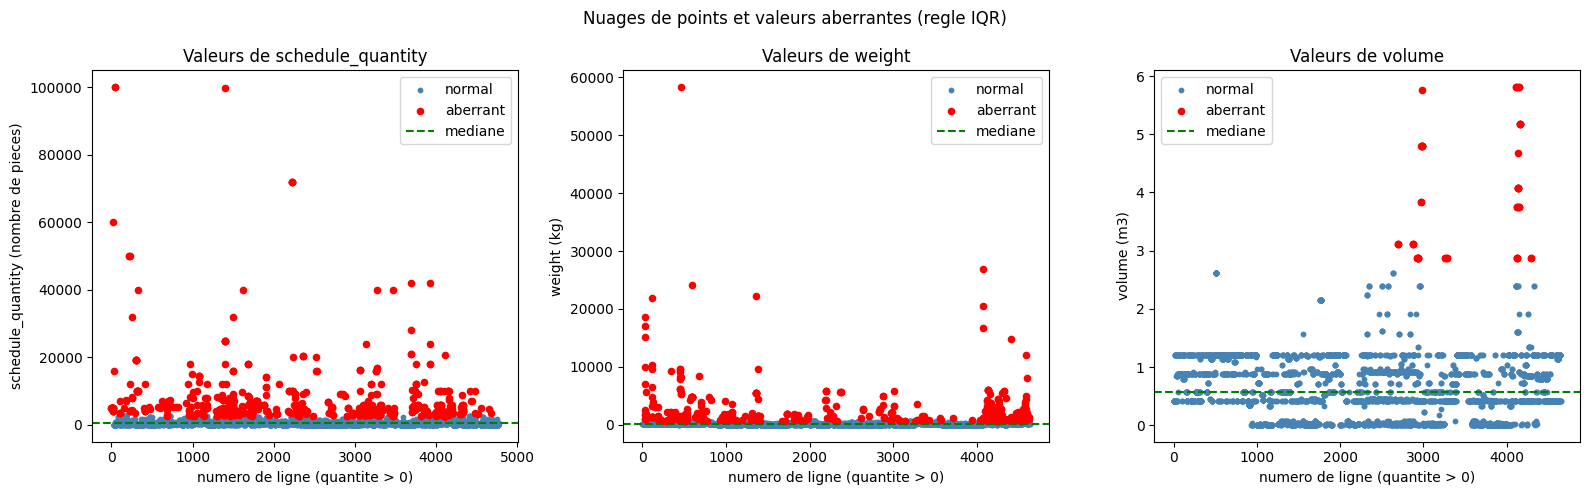

In [28]:
unites = {"schedule_quantity": "nombre de pieces", "weight": "kg", "volume": "m3"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, COLS_NUM):
    serie = base_ab[col].dropna()
    x = np.arange(len(serie))
    basse, haute = bornes_iqr(serie)
    est_aberrant = (serie.values < basse) | (serie.values > haute)

    ax.scatter(x[~est_aberrant], serie.values[~est_aberrant], s=10, color="steelblue", label="normal")
    ax.scatter(x[est_aberrant], serie.values[est_aberrant], s=20, color="red", label="aberrant")
    ax.axhline(serie.median(), color="green", linestyle="--", label="mediane")
    ax.set_title("Valeurs de " + col)
    ax.set_xlabel("numero de ligne (quantite > 0)")
    ax.set_ylabel(col + " (" + unites[col] + ")")
    ax.legend()

fig.suptitle("Nuages de points et valeurs aberrantes (regle IQR)")
plt.tight_layout()
plt.show()

Pour chaque colonne : les 10 lignes les plus éloignées de la médiane :

In [29]:
for col in COLS_NUM:
    mediane = base_ab[col].median()
    ecart = (base_ab[col] - mediane).abs()
    top = base_ab.assign(ecart_mediane=ecart.round(2)).sort_values("ecart_mediane", ascending=False)
    print("Colonne", col, "- mediane =", mediane)
    display(top.head(10)[["date", "supplier_id", "material", "plant", col, "ecart_mediane"]])

Colonne schedule_quantity - mediane = 400.0


,date,supplier_id,material,plant,schedule_quantity,ecart_mediane
58,2026-11-16,SUP_00091,MAT_001065,PLT_004,100000.0,99600.0
59,2027-01-01,SUP_00091,MAT_001065,PLT_004,100000.0,99600.0
1785,2027-01-01,SUP_00055,MAT_000671,PLT_001,99840.0,99440.0
2685,2026-12-16,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
2682,2026-11-19,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
2686,2027-01-01,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
2683,2026-12-02,SUP_00057,MAT_000239,PLT_001,72000.0,71600.0
26,2027-01-01,SUP_00091,MAT_000110,PLT_004,60000.0,59600.0
280,2027-01-01,SUP_00061,MAT_000105,PLT_004,50000.0,49600.0
279,2026-11-16,SUP_00061,MAT_000105,PLT_004,50000.0,49600.0


Colonne weight - mediane = 146.4


,date,supplier_id,material,plant,weight,ecart_mediane
610,2027-01-01,SUP_00117,MAT_000700,PLT_004,58267.30,58120.90
5015,2026-12-15,SUP_00074,MAT_001164,PLT_003,26905.20,26758.80
773,2027-01-01,SUP_00117,MAT_000655,PLT_004,24099.86,23953.46
1741,2027-01-01,SUP_00024,MAT_000159,PLT_001,22212.40,22066.00
147,2026-11-11,SUP_00046,MAT_000486,PLT_004,21826.80,21680.40
5014,2026-12-01,SUP_00074,MAT_001164,PLT_003,20499.20,20352.80
39,2026-12-02,SUP_00046,MAT_000194,PLT_004,18536.20,18389.80
36,2026-11-11,SUP_00046,MAT_000194,PLT_004,17012.60,16866.20
5013,2026-11-17,SUP_00074,MAT_001164,PLT_003,16655.60,16509.20
38,2026-11-25,SUP_00046,MAT_000194,PLT_004,15235.20,15088.80


Colonne volume - mediane = 0.57


,date,supplier_id,material,plant,volume,ecart_mediane
5099,2026-11-27,SUP_00037,MAT_000153,PLT_002,5.808,5.24
5061,2026-11-12,SUP_00037,MAT_000583,PLT_002,5.808,5.24
5098,2026-11-26,SUP_00037,MAT_000153,PLT_002,5.808,5.24
5066,2026-11-20,SUP_00037,MAT_001110,PLT_002,5.808,5.24
5067,2026-11-27,SUP_00037,MAT_001110,PLT_002,5.808,5.24
3570,2027-01-01,SUP_00005,MAT_000326,PLT_001,5.760,5.19
5107,2026-11-27,SUP_00037,MAT_000458,PLT_002,5.184,4.61
5104,2026-11-12,SUP_00037,MAT_000458,PLT_002,5.184,4.61
5105,2026-11-20,SUP_00037,MAT_000458,PLT_002,5.184,4.61
5106,2026-11-26,SUP_00037,MAT_000458,PLT_002,5.184,4.61


**Notre constat :** la règle IQR compte 1 183 valeurs « hors norme ». Ce ne sont pas des erreurs mais de vrais gros lots (jusqu'à 100 000 pièces, 58 tonnes) : nous les gardons. Sans le 1ᵉʳ janvier il en reste 1 124 : ce jour apporte surtout des lignes très lourdes.

### 2.A.8 Plausibilité métier

Nous confrontons les données au bon sens du projet : une ligne ne devrait pas
dépasser la capacité d'un camion, il ne devrait pas y avoir de besoin le
week-end, et la charge devrait se répartir normalement sur la semaine.

Lignes qui dépassent à elles seules la capacité d'un camion :

In [30]:
depasse_poids = schedule[schedule["weight"] > CAP_POIDS]
depasse_volume = schedule[schedule["volume"] > CAP_VOLUME]
print("Lignes dont le poids depasse", CAP_POIDS, "kg :", len(depasse_poids))
print("Lignes dont le volume depasse", CAP_VOLUME, "m3 :", len(depasse_volume))
if len(depasse_poids) > 0:
    display(depasse_poids[["date", "supplier_id", "material", "plant",
                           "schedule_quantity", "weight", "volume"]])

Lignes dont le poids depasse 24500.0 kg : 2
Lignes dont le volume depasse 110.4 m3 : 0


,date,supplier_id,material,plant,schedule_quantity,weight,volume
610,2027-01-01,SUP_00117,MAT_000700,PLT_004,5320.0,58267.3,1.1424
5015,2026-12-15,SUP_00074,MAT_001164,PLT_003,5670.0,26905.2,0.8400


Besoins tombant un samedi ou un dimanche :

In [31]:
d_besoin = pd.to_datetime(schedule["date"], errors="coerce")
jour_semaine = d_besoin.dt.dayofweek          # 0 = lundi ... 6 = dimanche
week_end = schedule[jour_semaine >= 5]
week_end_reels = week_end[week_end["schedule_quantity"] > 0]
print("Lignes datees d'un samedi/dimanche :", len(week_end))
print("  dont avec une quantite > 0       :", len(week_end_reels))

Lignes datees d'un samedi/dimanche : 0
  dont avec une quantite > 0       : 0


Répartition des lignes et du poids par jour de la semaine :

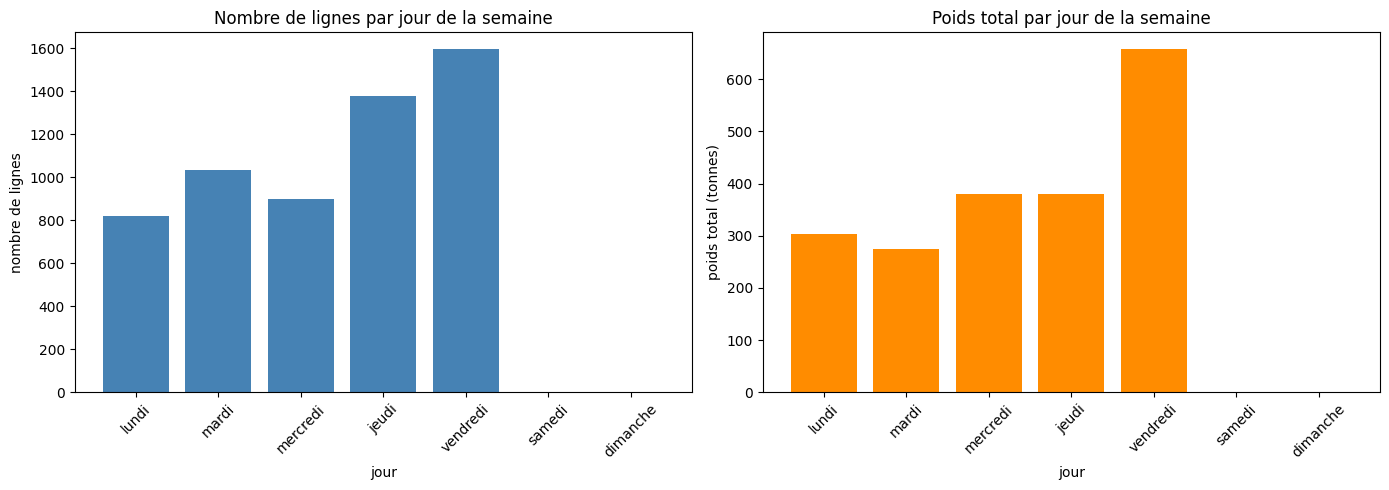

In [32]:
noms_jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
travail = schedule.assign(jour=jour_semaine)
nb_lignes_jour = travail.groupby("jour").size().reindex(range(7), fill_value=0)
poids_jour = travail.groupby("jour")["weight"].sum().reindex(range(7), fill_value=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(noms_jours, nb_lignes_jour.values, color="steelblue")
ax1.set_title("Nombre de lignes par jour de la semaine")
ax1.set_xlabel("jour"); ax1.set_ylabel("nombre de lignes")
ax1.tick_params(axis="x", rotation=45)

ax2.bar(noms_jours, poids_jour.values / 1000, color="darkorange")
ax2.set_title("Poids total par jour de la semaine")
ax2.set_xlabel("jour"); ax2.set_ylabel("poids total (tonnes)")
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Notre constat :** 2 lignes pèsent plus qu'un camion entier (24,5 t) : à répartir sur plusieurs camions. Aucun besoin le week-end.

### 2.A.9 Couverture temporelle

Nous vérifions que la période couverte est continue : semaines absentes,
semaines anormalement chargées ou vides, et nombre de versions du planning.

Période couverte :

In [33]:
d_besoin = pd.to_datetime(schedule["date"], errors="coerce")
print("Premiere date :", d_besoin.min().date())
print("Derniere date :", d_besoin.max().date())
print("Duree couverte :", (d_besoin.max() - d_besoin.min()).days, "jours")

# Sans le 1er janvier (point de rejet)
d_sans = pd.to_datetime(schedule_sans_jan["date"], errors="coerce")
print()
print("Sans le 1er janvier -> derniere vraie date :", d_sans.max().date())

Premiere date : 2026-11-09
Derniere date : 2027-01-01
Duree couverte : 53 jours

Sans le 1er janvier -> derniere vraie date : 2026-12-30


Semaines présentes et semaines manquantes entre la première et la dernière date (repère : le lundi de la semaine). Nous comptons aussi le nombre de lignes par semaine pour repérer les semaines **quasi vides**, typiquement l'**arrêt de Noël**, qu'une simple liste de semaines « présentes » ne voit pas.

In [34]:
semaine = d_besoin.dt.to_period("W")
semaines_presentes = pd.PeriodIndex(semaine.dropna().unique()).sort_values()
semaines_attendues = pd.period_range(semaines_presentes.min(), semaines_presentes.max(), freq="W")
semaines_manquantes = semaines_attendues.difference(semaines_presentes)

print("Nombre de semaines presentes :", len(semaines_presentes))
print("Nombre de semaines attendues :", len(semaines_attendues))
print("Semaines manquantes          :", len(semaines_manquantes))
for s in semaines_manquantes:
    print("  manquante :", s.start_time.date(), "->", s.end_time.date())

# Une semaine peut etre "presente" mais quasi vide (arret de Noel) : on compte les lignes.
lignes_par_sem = semaine.value_counts().sort_index()
seuil = 0.15 * lignes_par_sem.median()   # moins de 15 % d'une semaine normale = quasi vide
print()
print("Lignes par semaine (seuil quasi-vide =", round(seuil), ") :")
for p, nb_l in lignes_par_sem.items():
    marque = "  <-- QUASI VIDE (arret de Noel ?)" if nb_l < seuil else ""
    print("  ", p.start_time.date(), "->", p.end_time.date(), ":", int(nb_l), "lignes", marque)

Nombre de semaines presentes : 8
Nombre de semaines attendues : 8
Semaines manquantes          : 0

Lignes par semaine (seuil quasi-vide = 113 ) :
   2026-11-09 -> 2026-11-15 : 828 lignes 
   2026-11-16 -> 2026-11-22 : 922 lignes 
   2026-11-23 -> 2026-11-29 : 1446 lignes 
   2026-11-30 -> 2026-12-06 : 912 lignes 
   2026-12-07 -> 2026-12-13 : 673 lignes 
   2026-12-14 -> 2026-12-20 : 521 lignes 
   2026-12-21 -> 2026-12-27 : 3 lignes   <-- QUASI VIDE (arret de Noel ?)
   2026-12-28 -> 2027-01-03 : 423 lignes 


Nombre de lignes et poids total par semaine :

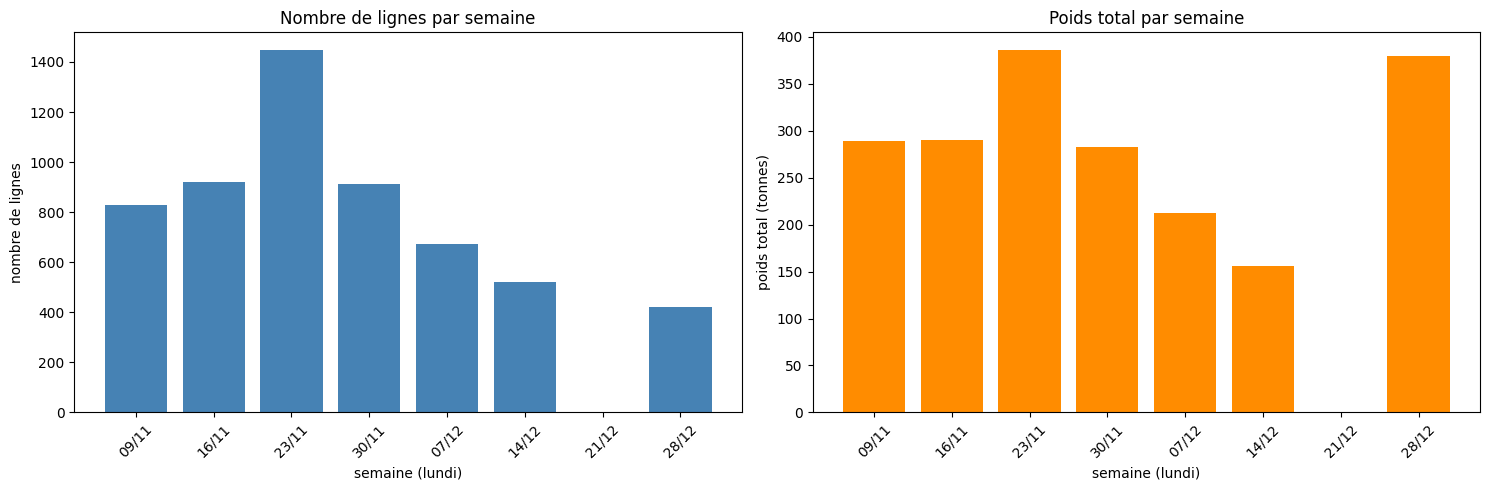

In [35]:
travail = schedule.assign(semaine=semaine.dt.start_time)
par_semaine = travail.groupby("semaine").agg(
    nb_lignes=("date", "size"),
    poids_total=("weight", "sum"),
).reset_index()
etiquettes = par_semaine["semaine"].dt.strftime("%d/%m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.bar(etiquettes, par_semaine["nb_lignes"], color="steelblue")
ax1.set_title("Nombre de lignes par semaine")
ax1.set_xlabel("semaine (lundi)"); ax1.set_ylabel("nombre de lignes")
ax1.tick_params(axis="x", rotation=45)

ax2.bar(etiquettes, par_semaine["poids_total"] / 1000, color="darkorange")
ax2.set_title("Poids total par semaine")
ax2.set_xlabel("semaine (lundi)"); ax2.set_ylabel("poids total (tonnes)")
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Nombre de versions du planning :

In [36]:
print("Nombre de versions (version_date) :", schedule["version_date"].nunique())
print("Valeur(s) :", list(schedule["version_date"].unique()))

Nombre de versions (version_date) : 1
Valeur(s) : ['2026-11-08']


**Notre constat :** le planning va du 9 novembre 2026 au 1ᵉʳ janvier 2027. Aucune semaine n'est totalement absente, **mais** la semaine de **Noël (du 21 au 27 décembre)** est quasi vide : 3 lignes, toutes à quantité 0, donc aucun vrai besoin (arrêt de l'usine pour les fêtes). Et la dernière semaine (28/12) est remplie presque uniquement par le 1ᵉʳ janvier « fourre-tout ». La vraie dernière date de travail est donc le **30 décembre**. Il n'y a qu'une seule version du planning.

### 2.A.10 Analyse par usine

C'est le cœur du projet : combien de camions faut-il par usine et par
semaine ? Nous comparons le minimum théorique (tout le poids de l'usine regroupé)
au calcul réaliste (un camion ne mélange pas deux fournisseurs).

Nombre de fournisseurs par usine et nombre de couples fournisseur x usine :

In [37]:
fourn_par_usine = schedule.groupby("plant")["supplier_id"].nunique()
print("Fournisseurs par usine :")
display(fourn_par_usine.to_frame("nb_fournisseurs"))
nb_couples = schedule[["supplier_id", "plant"]].drop_duplicates().shape[0]
print("Nombre de couples fournisseur x usine :", nb_couples)

Fournisseurs par usine :


,nb_fournisseurs
plant,
PLT_001,52
PLT_002,64
PLT_003,26
PLT_004,43


Nombre de couples fournisseur x usine : 185


Nous ne gardons que les vrais besoins (quantité > 0) et nous mettons à 0 les poids/volumes manquants (notre choix H4), pour pouvoir additionner par semaine sans inventer de valeurs.

In [38]:
# Notre base de travail pour les camions : uniquement les vrais besoins (quantite > 0).
# Les poids/volumes manquants sont mis a 0 (choix H4), pour pouvoir additionner sans inventer.
base10 = schedule[schedule["schedule_quantity"] > 0].copy()
base10["semaine"] = pd.to_datetime(base10["date"], errors="coerce").dt.to_period("W").dt.start_time
base10["weight"] = base10["weight"].fillna(0.0)
base10["volume"] = base10["volume"].fillna(0.0)
usines = sorted(base10["plant"].unique())
print("Lignes utiles (quantite > 0) :", len(base10))
print("Usines :", usines)

Lignes utiles (quantite > 0) : 4769
Usines : ['PLT_001', 'PLT_002', 'PLT_003', 'PLT_004']


Un graphique par usine : poids (tonnes, axe gauche) et volume (m³, axe droit) par semaine, en barres côte à côte.

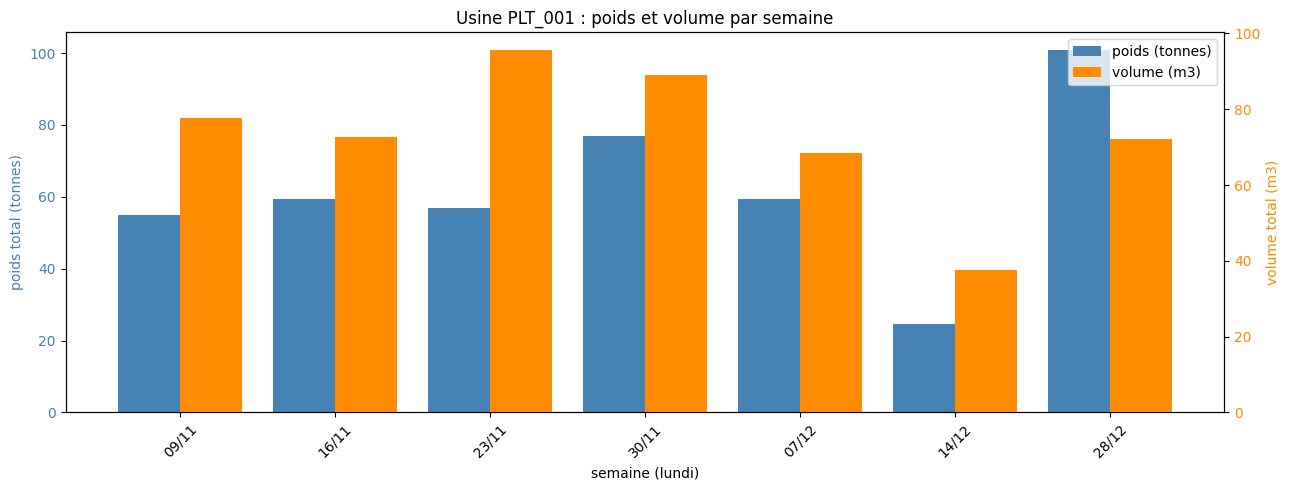

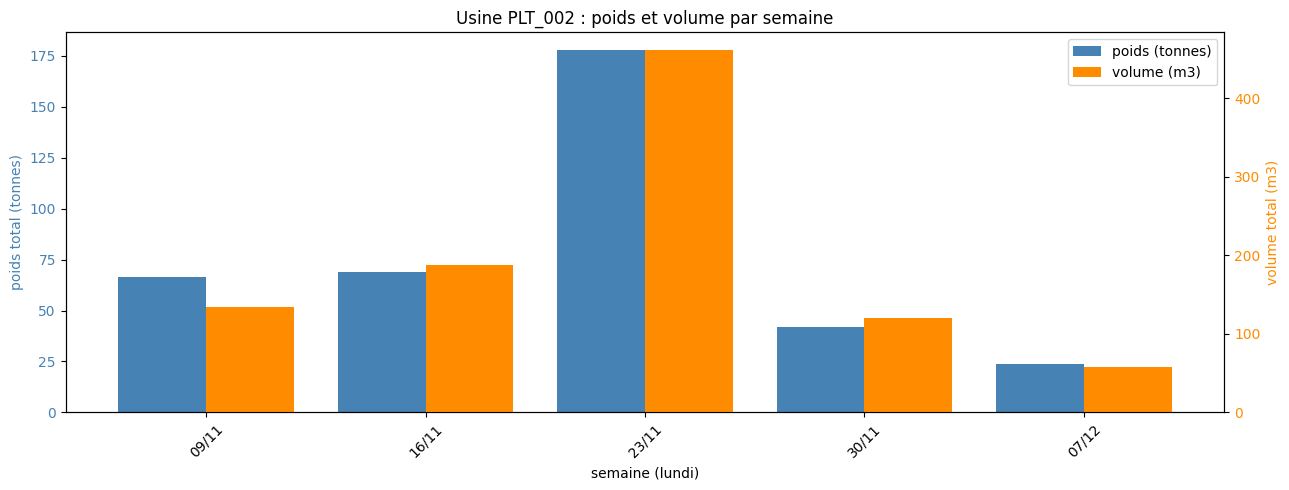

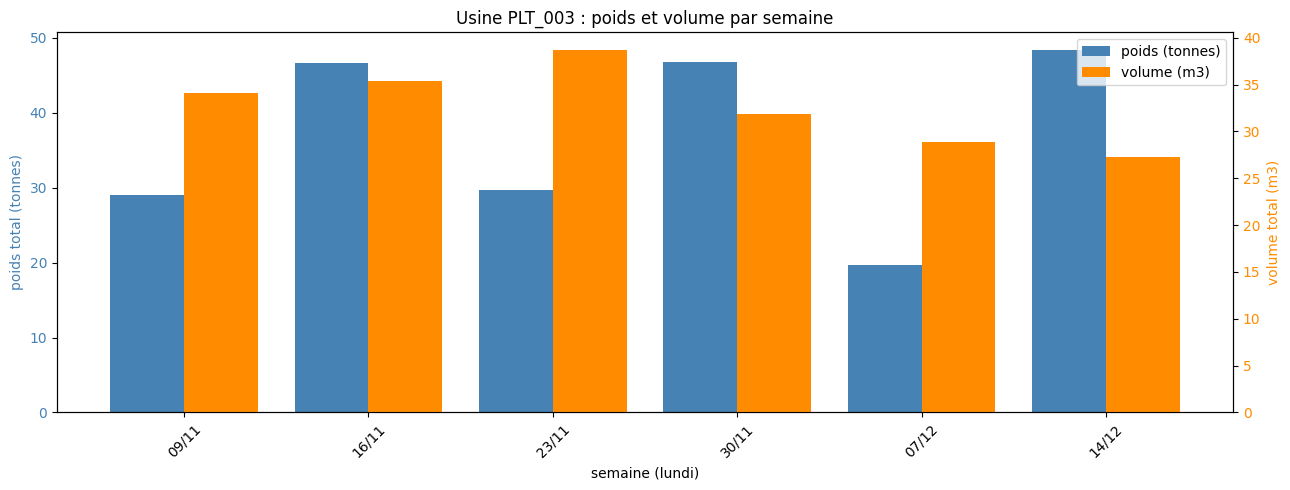

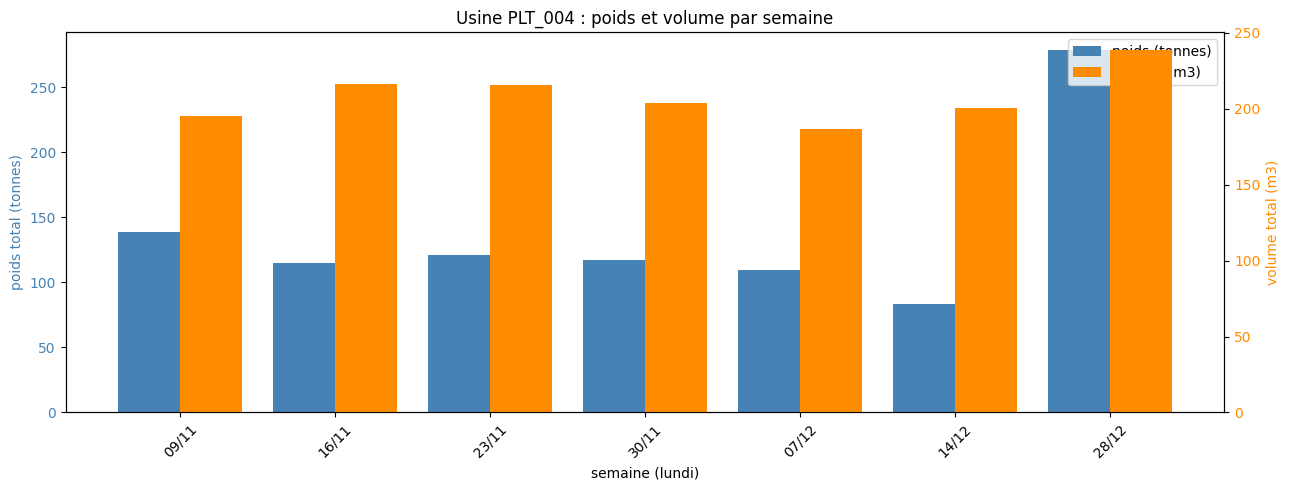

In [39]:
for usine in usines:
    sous = base10[base10["plant"] == usine]
    agg = sous.groupby("semaine").agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index()
    etiquettes = agg["semaine"].dt.strftime("%d/%m")
    x = np.arange(len(agg))
    largeur = 0.4

    fig, ax_poids = plt.subplots(figsize=(13, 5))
    ax_vol = ax_poids.twinx()
    ax_poids.bar(x - largeur / 2, agg["poids"] / 1000, width=largeur, color="steelblue", label="poids (tonnes)")
    ax_vol.bar(x + largeur / 2, agg["volume"], width=largeur, color="darkorange", label="volume (m3)")

    ax_poids.set_title("Usine " + usine + " : poids et volume par semaine")
    ax_poids.set_xlabel("semaine (lundi)")
    ax_poids.set_ylabel("poids total (tonnes)", color="steelblue")
    ax_vol.set_ylabel("volume total (m3)", color="darkorange")
    ax_poids.set_xticks(x); ax_poids.set_xticklabels(etiquettes, rotation=45)
    ax_poids.tick_params(axis="y", labelcolor="steelblue")
    ax_vol.tick_params(axis="y", labelcolor="darkorange")
    b1, l1 = ax_poids.get_legend_handles_labels()
    b2, l2 = ax_vol.get_legend_handles_labels()
    ax_poids.legend(b1 + b2, l1 + l2, loc="upper right")
    plt.tight_layout()
    plt.show()

Nombre de camions nécessaires par usine et par semaine.
Règle : camions = max(arrondi supérieur(poids / 24 500), arrondi supérieur(volume / 110,4)).
Version **a** = tout regroupé par usine (borne basse théorique) ; version **b** = par couple fournisseur x usine, puis somme. La version b respecte la règle R3 (un camion = un seul fournisseur), c'est notre scénario réel.

In [40]:
def nb_camions(poids, volume):
    return max(int(np.ceil(poids / CAP_POIDS)), int(np.ceil(volume / CAP_VOLUME)))

# Version a : minimum theorique
theorique = (base10.groupby(["plant", "semaine"])
             .agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index())
theorique["camions_a"] = theorique.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1)

# Version b : realiste, par couple fournisseur x usine
par_couple = (base10.groupby(["plant", "semaine", "supplier_id"])
              .agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index())
par_couple["camions"] = par_couple.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1)
par_couple["camions_poids"] = np.ceil(par_couple["poids"] / CAP_POIDS).astype(int)
par_couple["camions_volume"] = np.ceil(par_couple["volume"] / CAP_VOLUME).astype(int)
par_couple["limite"] = np.where(par_couple["camions_poids"] >= par_couple["camions_volume"], "poids", "volume")

realiste = (par_couple.groupby(["plant", "semaine"])["camions"].sum()
            .reset_index().rename(columns={"camions": "camions_b"}))

comparaison = theorique.merge(realiste, on=["plant", "semaine"])
comparaison.head(12)

,plant,semaine,poids,volume,camions_a,camions_b
0,PLT_001,2026-11-09,55068.23,77.582960,3,41
1,PLT_001,2026-11-16,59337.29,72.780195,3,37
2,PLT_001,2026-11-23,56981.46,95.501563,3,40
3,PLT_001,2026-11-30,76811.16,88.900286,4,43
4,PLT_001,2026-12-07,59274.66,68.355150,3,35
5,PLT_001,2026-12-14,24648.86,37.570800,2,25
6,PLT_001,2026-12-28,100737.25,72.032760,5,31
7,PLT_002,2026-11-09,66242.46,134.386136,3,37
8,PLT_002,2026-11-16,68838.62,187.530326,3,45
9,PLT_002,2026-11-23,177551.14,460.620305,8,56


Quelle limite (poids ou volume) déclenche le plus souvent un camion ?

In [41]:
actifs = par_couple[par_couple["camions"] > 0]
display(actifs["limite"].value_counts().to_frame("nb_couples"))
part_volume = (actifs["limite"] == "volume").mean()
print("Le volume est", "souvent" if part_volume > 0.5 else "rarement", "la contrainte la plus serrante.")

,nb_couples
limite,
poids,775
volume,3


Le volume est rarement la contrainte la plus serrante.


Diagramme en barres groupées : semaines en abscisse, une couleur par usine (version réaliste b).

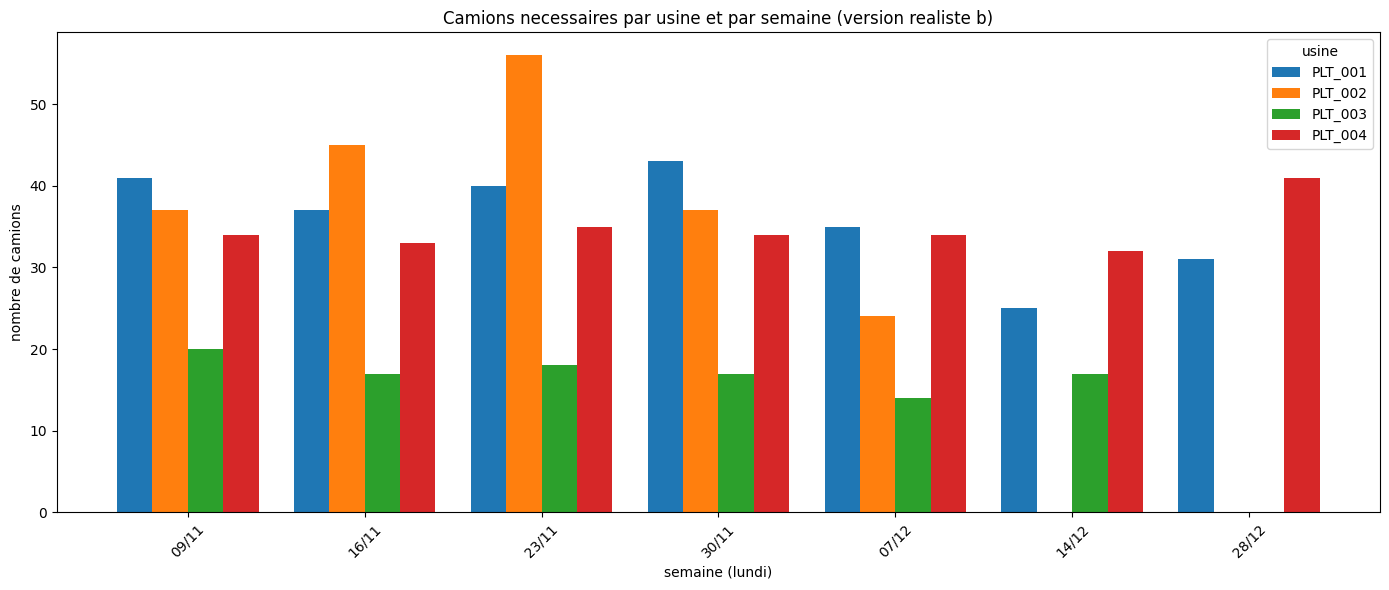

In [42]:
pivot = realiste.pivot(index="semaine", columns="plant", values="camions_b").fillna(0)
etiquettes = pivot.index.strftime("%d/%m")
x = np.arange(len(pivot))
n_usines = pivot.shape[1]
largeur = 0.8 / n_usines

fig, ax = plt.subplots(figsize=(14, 6))
for i, usine in enumerate(pivot.columns):
    ax.bar(x + (i - (n_usines - 1) / 2) * largeur, pivot[usine].values, width=largeur, label=usine)
ax.set_title("Camions necessaires par usine et par semaine (version realiste b)")
ax.set_xlabel("semaine (lundi)"); ax.set_ylabel("nombre de camions")
ax.set_xticks(x); ax.set_xticklabels(etiquettes, rotation=45)
ax.legend(title="usine")
plt.tight_layout()
plt.show()

Comparaison globale théorique (a) vs réaliste (b) :

In [43]:
total_a = int(comparaison["camions_a"].sum())
total_b = int(comparaison["camions_b"].sum())
print("Total camions, version a (minimum theorique) :", total_a)
print("Total camions, version b (realiste)          :", total_b)
print("Surcout du au non-melange des fournisseurs :", total_b - total_a, "camions")

# Meme calcul sans le 1er janvier (point de rejet)
base10_sans = base10[base10["date"] != JOUR_REJET]
th_s = base10_sans.groupby(["plant", "semaine"]).agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index()
a_s = int(th_s.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1).sum())
pc_s = base10_sans.groupby(["plant", "semaine", "supplier_id"]).agg(poids=("weight", "sum"), volume=("volume", "sum")).reset_index()
b_s = int(pc_s.apply(lambda r: nb_camions(r["poids"], r["volume"]), axis=1).sum())
print()
print("Sans le 1er janvier :")
print("  minimum theorique (a)   :", a_s)
print("  realiste par couple (b) :", b_s)
print("  -> le 1er janvier pese", total_b - b_s, "camions sur", total_b)

Total camions, version a (minimum theorique) : 93
Total camions, version b (realiste)          : 797
Surcout du au non-melange des fournisseurs : 704 camions

Sans le 1er janvier :
  minimum theorique (a)   : 76
  realiste par couple (b) : 725
  -> le 1er janvier pese 72 camions sur 797


**Notre constat :** la version a (tout regrouper par usine) n'est pas un objectif pour nous : la règle R3 l'interdit (un camion = un seul fournisseur). La version b correspond à notre scénario « 1 livraison par semaine par couple ». Sur la période, elle demande **797 camions** (725 si nous sortons le 1er janvier). Notre vrai levier : passer des **1 731 livraisons actuelles** (couple x jour) à **797 camions**. Et c'est presque toujours le **poids** qui remplit le camion, pas le volume.

### 2.B Les distances (`distances.csv`)

Ce fichier nous donne, pour chaque fournisseur, la **distance en km** jusqu'au point de consolidation. Elle nous sert à choisir la **ligne de la grille tarifaire** (une distance prend la tranche supérieure, ex. 47 km -> tranche 50). Pour les croisements, nous utilisons le planning déjà chargé (`schedule`), sur les lignes avec **quantité > 0**.

### 2.B.1 Vue d'ensemble
Nous regardons la taille du fichier et le type de chaque colonne.

In [44]:
print("Dimensions :", distances.shape[0], "lignes,", distances.shape[1], "colonnes")
print()
print(distances.dtypes.to_frame(name="type"))
distances.head()

Dimensions : 156 lignes, 2 colonnes

                type
supplier_id   object
distance     float64


,supplier_id,distance
0,SUP_00001,47.0
1,SUP_00002,NaN
2,SUP_00003,83.0
3,SUP_00004,95.0
4,SUP_00005,46.0


**Notre constat :** 156 lignes et 2 colonnes : `supplier_id` (texte) et `distance` (nombre). Une ligne = un fournisseur et sa distance au point de consolidation.

### 2.B.2 Profilage
Distances min, max, moyenne, médiane ; nombre de fournisseurs ; valeurs entières ou décimales.

In [45]:
d = distances["distance"]
print("Distance min     :", d.min(), "km")
print("Distance max     :", d.max(), "km")
print("Distance moyenne :", round(d.mean(), 2), "km")
print("Distance mediane :", d.median(), "km")
print("Fournisseurs distincts :", distances["supplier_id"].nunique())
print("Distances toutes entieres :", bool((d.dropna() % 1 == 0).all()))

Distance min     : 6.0 km
Distance max     : 149.0 km
Distance moyenne : 59.44 km
Distance mediane : 55.0 km
Fournisseurs distincts : 156
Distances toutes entieres : True


**Notre constat :** les distances vont de **6 à 149 km** (moyenne 59, médiane 55). 156 fournisseurs distincts. Toutes les distances sont des **entiers** (en km), même si stockées en décimal.

### 2.B.3 Complétude
Combien de distances vides, quelle proportion, et quels fournisseurs ?

In [46]:
nb_vide = int(distances["distance"].isna().sum())
print("Distances vides :", nb_vide, "sur", len(distances),
      "(", round(nb_vide / len(distances) * 100, 2), "% )")
print("Fournisseurs concernes :")
print(distances.loc[distances["distance"].isna(), "supplier_id"].tolist())

Distances vides : 11 sur 156 ( 7.05 % )
Fournisseurs concernes :
['SUP_00002', 'SUP_00012', 'SUP_00030', 'SUP_00031', 'SUP_00047', 'SUP_00050', 'SUP_00084', 'SUP_00115', 'SUP_00130', 'SUP_00137', 'SUP_00141']


**Notre constat :** **11 distances manquantes** sur 156 (7,05 %), pour les fournisseurs SUP_00002, 00012, 00030, 00031, 00047, 00050, 00084, 00115, 00130, 00137, 00141. L'impact dépend de leur présence dans le planning.

### 2.B.4 Unicité
Un fournisseur apparaît-il plusieurs fois ? Avec des distances différentes ?

In [47]:
nb_dup = int(distances["supplier_id"].duplicated().sum())
print("Fournisseurs en double :", nb_dup)
multi = distances.groupby("supplier_id")["distance"].nunique()
print("Fournisseurs avec plusieurs distances differentes :", int((multi > 1).sum()))

Fournisseurs en double : 0
Fournisseurs avec plusieurs distances differentes : 0


**Notre constat :** aucun doublon. Chaque fournisseur apparaît **une seule fois**, avec une seule distance : pas de valeurs contradictoires.

### 2.B.5 Validité
Les identifiants ont-ils le format SUP_ + 5 chiffres ? Des distances négatives ou nulles ?

In [48]:
conforme = distances["supplier_id"].astype(str).str.match(r"^SUP_\d{5}$")
print("Identifiants non conformes :", int((~conforme).sum()))
print("Distances negatives :", int((distances["distance"] < 0).sum()))
print("Distances egales a 0 :", int((distances["distance"] == 0).sum()))

Identifiants non conformes : 0
Distances negatives : 0
Distances egales a 0 : 0


**Notre constat :** données **valides** : tous les identifiants au format SUP_ + 5 chiffres, aucune distance négative ni nulle.

### 2.B.6 Valeurs aberrantes et plausibilité
Répartition des distances (histogramme) et distances très éloignées des autres (nuage de points, médiane, aberrants en rouge selon Q1/Q3 +/- 1,5 x IQR).

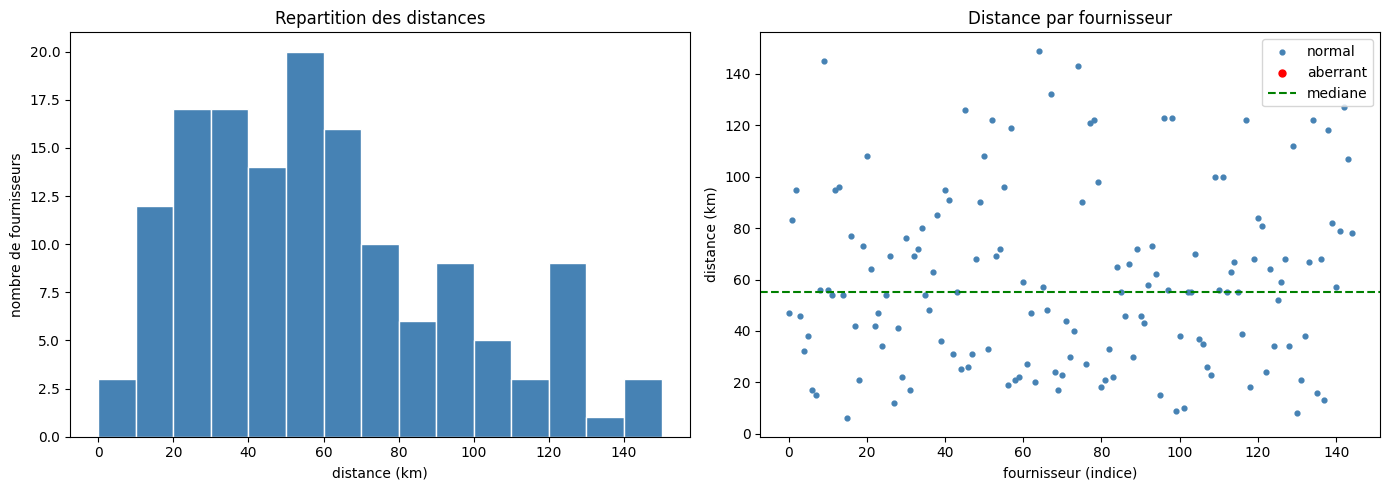

Bornes IQR : [ -38.5 , 149.5 ] km  ->  aberrants : 0


In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme de repartition
ax1.hist(distances["distance"].dropna(), bins=range(0, 160, 10), color="steelblue", edgecolor="white")
ax1.set_title("Repartition des distances")
ax1.set_xlabel("distance (km)")
ax1.set_ylabel("nombre de fournisseurs")

# Nuage de points avec regle IQR
d = distances["distance"].dropna()
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr = q3 - q1
basse, haute = q1 - 1.5 * iqr, q3 + 1.5 * iqr
ab = (d < basse) | (d > haute)
x = np.arange(len(d))
ax2.scatter(x[~ab.values], d.values[~ab.values], s=12, color="steelblue", label="normal")
ax2.scatter(x[ab.values], d.values[ab.values], s=25, color="red", label="aberrant")
ax2.axhline(d.median(), color="green", linestyle="--", label="mediane")
ax2.set_title("Distance par fournisseur")
ax2.set_xlabel("fournisseur (indice)")
ax2.set_ylabel("distance (km)")
ax2.legend()

plt.tight_layout()
plt.show()
print("Bornes IQR : [", round(basse, 1), ",", round(haute, 1), "] km  ->  aberrants :", int(ab.sum()))

**Notre constat :** les distances sont **réalistes pour du transport routier régional** (6 à 149 km). La règle IQR (bornes -38 à 150 km) ne signale **aucune valeur aberrante** : pas de distance absurde à corriger.

### 2.B.7 Lien avec le planning
Fournisseurs du planning absents du fichier distances, et l'inverse. Les fournisseurs sans distance sont-ils actifs ? Si oui : combien de lignes, de kg, de m3, et quelle part du poids total ?

In [50]:
f_plan = set(schedule.loc[schedule["schedule_quantity"] > 0, "supplier_id"].unique())
f_dist = set(distances["supplier_id"].unique())
print("Fournisseurs actifs du planning (qte>0) :", len(f_plan))
print("Fournisseurs dans distances            :", len(f_dist))
print("Planning absents de distances          :", sorted(f_plan - f_dist))
print("Distances absents du planning          :", len(f_dist - f_plan), "(references mais non actifs)")
print()

sans_dist = set(distances.loc[distances["distance"].isna(), "supplier_id"])
actifs_sans_dist = sorted(sans_dist & f_plan)
print("Fournisseurs actifs SANS distance :", actifs_sans_dist)
sub = schedule[(schedule["schedule_quantity"] > 0) & (schedule["supplier_id"].isin(actifs_sans_dist))]
poids_total = schedule.loc[schedule["schedule_quantity"] > 0, "weight"].sum()
print("  lignes :", len(sub), "| kg :", round(sub["weight"].sum()), "| m3 :", round(sub["volume"].sum(), 2))
print("  part du poids total du planning :", round(sub["weight"].sum() / poids_total * 100, 2), "%")

Fournisseurs actifs du planning (qte>0) : 94
Fournisseurs dans distances            : 156
Planning absents de distances          : []
Distances absents du planning          : 62 (references mais non actifs)

Fournisseurs actifs SANS distance : ['SUP_00047', 'SUP_00130']
  lignes : 5 | kg : 632 | m3 : 5.22
  part du poids total du planning : 0.03 %


**Notre constat :** les **94 fournisseurs actifs** du planning sont **tous présents** dans le fichier distances. À l'inverse, **62 fournisseurs** du fichier n'apparaissent pas dans le planning (référencés mais non actifs sur la période). Parmi les 11 sans distance, seuls **2** sont actifs (SUP_00047, SUP_00130) : 5 lignes, 632 kg, 5,22 m3, soit **0,03 % du poids total**. Impact négligeable, mais à compléter.

### 2.B.9 Compréhension : la distance dépend-elle de l'usine ?
Nous vérifions si une distance est propre au fournisseur (point de consolidation) ou varie selon l'usine livrée.

In [51]:
print("Colonnes de distances :", list(distances.columns))
print("Lignes par fournisseur (max) :", int(distances["supplier_id"].value_counts().max()))
multi = schedule[schedule["schedule_quantity"] > 0].groupby("supplier_id")["plant"].nunique()
print("Fournisseurs livrant plusieurs usines :", int((multi > 1).sum()), "sur", multi.size)
print("-> une seule distance par fournisseur, identique quelle que soit l'usine")

Colonnes de distances : ['supplier_id', 'distance']
Lignes par fournisseur (max) : 1
Fournisseurs livrant plusieurs usines : 52 sur 94
-> une seule distance par fournisseur, identique quelle que soit l'usine


**Notre constat :** le fichier donne **une seule distance par fournisseur**, sans colonne usine. La distance est donc la distance **fournisseur -> point de consolidation**, identique pour toutes les usines. D'ailleurs 52 des 94 fournisseurs actifs livrent plusieurs usines avec cette même distance unique : cohérent avec un schéma de consolidation.

### 2.C La grille tarifaire (`rate_sheet.pdf`)

La grille nous donne le coût d'un envoi selon la **distance** (lignes) et le **poids** (colonnes). Nous lisons le PDF avec pdfplumber, puis nous appliquons notre formule : **prix final = coût grille x (1 + 2,3923) x 1,1943** (marge + diesel, règle R5).

### 2.C.1 Lecture de la grille
Nous vérifions que nous avons bien lu le tableau : ses dimensions, l'absence de case vide, et que tout est bien numérique.

In [52]:
import pdfplumber

MARGE, DIESEL = 2.3923, 1.1943  # marge et coefficient diesel (R5)

with pdfplumber.open("../docs/rate_sheet.pdf") as pdf:
    tableau = pdf.pages[0].extract_tables()[0]

# 1re ligne = en-tete (tranches de poids) ; 1re colonne = tranches de distance
entete = tableau[0]
grille = pd.DataFrame(tableau[1:], columns=entete).set_index(entete[0])
# conversion en nombres (les valeurs sont des chaines)
grille = grille.apply(lambda col: col.map(lambda x: float(str(x).replace(",", "."))))

# prix final = cout grille x (1 + marge) x diesel
prix = grille * (1 + MARGE) * DIESEL

print("Dimensions de la grille :", grille.shape, "(lignes distance x colonnes poids)")
print("Cases vides             :", int(grille.isna().sum().sum()))
print("Tranches de distance (km) :", list(grille.index))
print("Tranches de poids (kg)    :", list(grille.columns))
grille.head()

Dimensions de la grille : (14, 15) (lignes distance x colonnes poids)
Cases vides             : 0
Tranches de distance (km) : ['30', '50', '75', '100', '125', '150', '175', '200', '250', '300', '400', '500', '650', '>650']
Tranches de poids (kg)    : ['50', '100', '200', '300', '400', '500', '750', '1000', '1500', '2000', '2500', '3000', '3500', '4000', '>4000']


,50,100,200,300,400,500,750,1000,1500,2000,2500,3000,3500,4000,>4000
km \ kg,,,,,,,,,,,,,,,
30,4.75,6.66,8.56,10.73,13.06,14.75,17.75,22.35,25.67,31.40,35.08,35.16,37.73,40.87,42.42
50,5.78,7.94,10.74,13.07,15.45,17.35,20.96,25.32,30.05,35.97,40.52,42.90,47.04,51.05,52.80
75,6.92,9.54,13.14,15.99,18.43,20.59,24.96,29.02,35.52,41.70,47.33,52.58,57.55,62.30,64.28
100,7.33,10.27,14.35,17.61,20.40,22.88,27.96,32.63,40.20,47.30,53.77,59.79,65.47,70.89,73.04
125,7.77,10.99,15.57,19.24,22.37,25.17,30.95,36.25,44.89,52.91,60.21,66.99,73.38,79.47,81.80


**Notre constat :** nous lisons une grille de **14 lignes x 15 colonnes**, **sans aucune case vide** et **entièrement numérique**. Les lignes sont les tranches de distance (30 à >650 km), les colonnes les tranches de poids (50 à >4000 kg). Nous pouvons l'utiliser directement.

### 2.C.2 Cohérence et vérification
Le prix doit toujours augmenter avec la distance et avec le poids. Et nous devons retrouver l'exemple du PDF : 300 km, 1 000 kg -> 335,34 EUR.

In [53]:
# Le prix augmente-t-il toujours avec la distance (le long d'une colonne) ?
croit_distance = all((grille[c].values[1:] >= grille[c].values[:-1]).all() for c in grille.columns)
# ... et avec le poids (le long d'une ligne) ?
croit_poids = all((grille.loc[r].values[1:] >= grille.loc[r].values[:-1]).all() for r in grille.index)
grille_monotone = bool(croit_distance and croit_poids)
print("Prix croissant avec la distance :", croit_distance)
print("Prix croissant avec le poids    :", croit_poids)

# Verification de l'exemple du PDF
exemple = prix.loc["300", "1000"]
print()
print("Exemple 300 km / 1000 kg :", round(exemple, 2), "EUR  (attendu : 335,34)")

Prix croissant avec la distance : True
Prix croissant avec le poids    : True

Exemple 300 km / 1000 kg : 335.34 EUR  (attendu : 335,34)


**Notre constat :** la grille est **cohérente** : le prix augmente toujours avec la distance et avec le poids. Et nous retrouvons **exactement** l'exemple du PDF (335,34 EUR pour 300 km / 1 000 kg). Notre lecture et notre formule sont donc justes.

### 2.C.3 Nos distances dans la grille
Nous regardons dans quelles lignes de la grille tombent les distances de nos fournisseurs actifs, et lesquelles ne nous servent jamais.

In [54]:
tranches_km = [30, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400, 500, 650]

def ligne_grille(km):
    # une distance prend la tranche superieure (ex. 47 -> "50")
    if pd.isna(km):
        return None
    for t in tranches_km:
        if km <= t:
            return str(t)
    return ">650"

f_actifs = schedule.loc[schedule["schedule_quantity"] > 0, "supplier_id"].unique()
d_actifs = distances[distances["supplier_id"].isin(f_actifs)].copy()
d_actifs["ligne_grille"] = d_actifs["distance"].apply(ligne_grille)

lignes_utilisees = [l for l in grille.index if l in set(d_actifs["ligne_grille"])]
lignes_inutiles = [l for l in grille.index if l not in set(d_actifs["ligne_grille"])]
print("Lignes de grille que nous utilisons :", lignes_utilisees)
print("Lignes de grille jamais utilisees   :", lignes_inutiles)
print("Fournisseurs sous 30 km             :", int((d_actifs["distance"] <= 30).sum()))

Lignes de grille que nous utilisons : ['30', '50', '75', '100', '125', '150']
Lignes de grille jamais utilisees   : ['175', '200', '250', '300', '400', '500', '650', '>650']
Fournisseurs sous 30 km             : 21


**Notre constat :** toutes nos distances tombent entre 30 et 150 km, dont **21 fournisseurs** sous 30 km : **seules les 6 premières lignes de la grille (30 à 150 km) nous servent**. Les 8 lignes au-delà ne nous servent jamais. Pour notre chiffrage, seul le haut de la grille compte.

### 2.C.4 Le prix au kg selon la taille de l'envoi
C'est le coeur de notre démarche : nous regardons, pour une distance typique (tranche 50 km), combien coûte 1 kg selon la taille de l'envoi. Plus l'envoi est gros, moins le kg coûte cher : c'est ce qui justifie le regroupement.

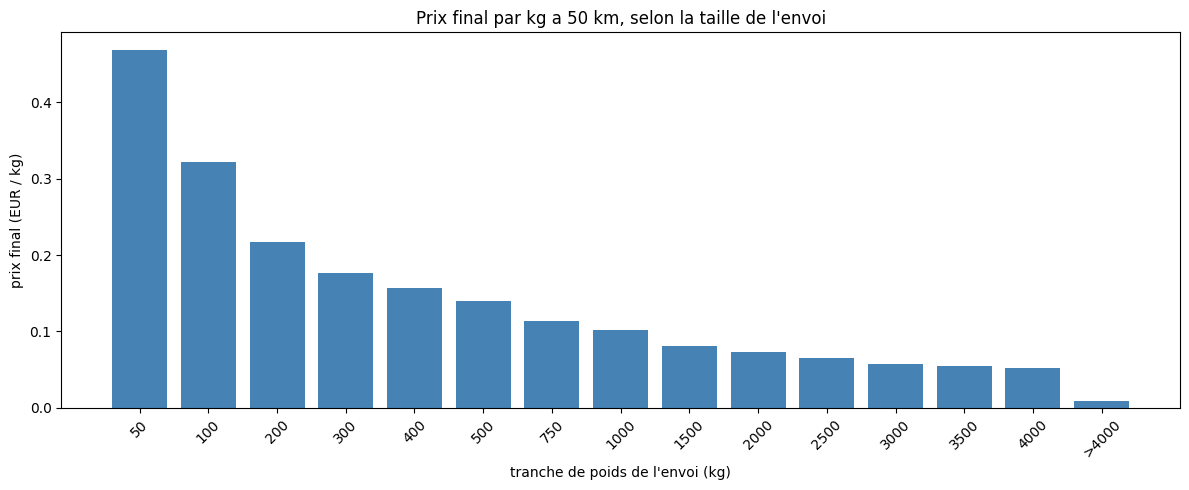

A 50 km :
  envoi de 50 kg   : 0.468 EUR/kg
  envoi de 1000 kg : 0.103 EUR/kg
  camion plein     : 0.0087 EUR/kg


In [55]:
# poids representatif de chaque tranche (borne haute ; camion plein pour ">4000")
poids_repr = {c: (24500 if c == ">4000" else int(c)) for c in grille.columns}
prix_par_kg_50 = pd.Series({c: prix.loc["50", c] / poids_repr[c] for c in grille.columns})

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(prix_par_kg_50.index, prix_par_kg_50.values, color="steelblue")
ax.set_title("Prix final par kg a 50 km, selon la taille de l'envoi")
ax.set_xlabel("tranche de poids de l'envoi (kg)")
ax.set_ylabel("prix final (EUR / kg)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("A 50 km :")
print("  envoi de 50 kg   :", round(prix_par_kg_50["50"], 3), "EUR/kg")
print("  envoi de 1000 kg :", round(prix_par_kg_50["1000"], 3), "EUR/kg")
print("  camion plein     :", round(prix_par_kg_50[">4000"], 4), "EUR/kg")

**Notre constat :** à 50 km, un petit envoi de 50 kg coûte **0,47 EUR/kg**, un envoi de 1 000 kg **0,10 EUR/kg**, et un camion plein **0,009 EUR/kg**. Le prix au kg **s'effondre quand l'envoi grossit**. C'est exactement pourquoi nous voulons regrouper : remplir les camions fait chuter le coût unitaire.

### 2.C.5 Camion plein contre petit envoi
Nous chiffrons l'écart entre un camion plein (24 500 kg, tarif « >4000 » confirmé par le client, H12) et un petit envoi de 300 kg, à 50 km.

In [56]:
cout_plein = prix.loc["50", ">4000"]          # un camion plein (24 500 kg)
cout_300 = prix.loc["50", "300"]              # un envoi de 300 kg
kg_plein = cout_plein / 24500
kg_300 = cout_300 / 300

print("A 50 km :")
print("  camion plein (24 500 kg) :", round(cout_plein, 2), "EUR  ->", round(kg_plein, 4), "EUR/kg")
print("  petit envoi (300 kg)     :", round(cout_300, 2), "EUR  ->", round(kg_300, 4), "EUR/kg")
print("  le petit envoi coute", round(kg_300 / kg_plein, 1), "fois plus cher par kg")

A 50 km :
  camion plein (24 500 kg) : 213.92 EUR  -> 0.0087 EUR/kg
  petit envoi (300 kg)     : 52.95 EUR  -> 0.1765 EUR/kg
  le petit envoi coute 20.2 fois plus cher par kg


**Notre constat :** à 50 km, le kg transporté dans un **camion plein coûte ~20 fois moins cher** que dans un envoi de 300 kg (0,009 contre 0,18 EUR/kg). Chaque camion que nous remplissons au lieu d'en faire partir deux à moitié vides est une économie directe. C'est la preuve chiffrée de l'intérêt de notre projet.

### 2.D Bilan de la qualité des données

### 2.D.1 Indicateurs clés
Les chiffres qui cadrent le projet et montrent l'enjeu (des camions aujourd'hui presque vides).

In [57]:
pos = schedule[schedule["schedule_quantity"] > 0]
lignes_utiles = len(pos)
couples = pos.groupby(["supplier_id", "plant"]).ngroups
livraisons = pos.groupby(["date", "supplier_id", "plant"]).ngroups
poids_liv = pos.groupby(["date", "supplier_id", "plant"])["weight"].sum()
remplissage_median = (poids_liv / CAP_POIDS * 100).median()

# Lignes utiles dont nous ignorons le poids (sur quantite > 0)
nb_poids_inconnu = int(pos["weight"].isna().sum())
pct_poids_inconnu = nb_poids_inconnu / lignes_utiles * 100

# Poids que nous ne pouvons pas chiffrer faute de distance (fournisseurs actifs sans distance)
f_actifs = set(pos["supplier_id"].unique())
sans_distance = set(distances.loc[distances["distance"].isna(), "supplier_id"]) & f_actifs
poids_total_utile = pos["weight"].sum()
poids_sans_prix = pos.loc[pos["supplier_id"].isin(sans_distance), "weight"].sum()
pct_poids_sans_prix = poids_sans_prix / poids_total_utile * 100

print("NOS INDICATEURS CLES")
print("Lignes utiles (quantite > 0)               :", lignes_utiles)
print("Couples fournisseur x usine                :", couples)
print("Livraisons actuelles (jour/fourn/usine)    :", livraisons)
print("Remplissage median d'un camion             :", round(remplissage_median, 1), "%")
print("Lignes utiles au poids inconnu             :", nb_poids_inconnu,
      "(", round(pct_poids_inconnu, 2), "% )")
print("Poids non chiffrable faute de distance     :", round(pct_poids_sans_prix, 3), "%")

NOS INDICATEURS CLES
Lignes utiles (quantite > 0)               : 4769
Couples fournisseur x usine                : 181
Livraisons actuelles (jour/fourn/usine)    : 1731
Remplissage median d'un camion             : 1.3 %
Lignes utiles au poids inconnu             : 139 ( 2.91 % )
Poids non chiffrable faute de distance     : 0.032 %


**Notre constat :** aujourd'hui **1 731 livraisons** desservent **181 couples** fournisseur x usine, avec un **remplissage médian de 1,3 % d'un camion** : nos camions partent quasiment vides. C'est tout l'enjeu de notre consolidation. Nous ignorons le poids de **139 lignes utiles (2,91 %)**, que nous mettons à 0 avec un indicateur. Et seul **0,03 %** du poids échappe au chiffrage faute de distance : l'impact est négligeable.

### 2.D.2 Tableau de synthèse des anomalies
Une ligne par anomalie, sur les deux fichiers, triée par impact (le plus grave en premier). Le % est calculé sur le fichier concerné.

In [58]:
n_plan = len(schedule)
n_dist = len(distances)
pos = schedule[schedule["schedule_quantity"] > 0]
n_utile = len(pos)
f_plan = set(pos["supplier_id"].unique())
actifs_sans_dist = set(distances.loc[distances["distance"].isna(), "supplier_id"]) & f_plan

anomalies = [
    {"anomalie": "Poids > capacite camion", "fichier": "planning",
     "nombre": int((schedule["weight"] > CAP_POIDS).sum()), "base": n_plan,
     "impact": "bloquant", "decision": "nous scindons la ligne sur plusieurs camions (H3)"},
    {"anomalie": "1er janvier 2027 (fourre-tout)", "fichier": "planning",
     "nombre": int((schedule["date"] == "2027-01-01").sum()), "base": n_plan,
     "impact": "a traiter", "decision": "nous retirons ces lignes (date fourre-tout confirmee par le client)"},
    {"anomalie": "Poids manquant sur ligne utile", "fichier": "planning",
     "nombre": int(pos["weight"].isna().sum()), "base": n_utile,
     "impact": "a traiter", "decision": "nous mettons a 0 + indicateur (H4)"},
    {"anomalie": "Volume manquant sur ligne utile", "fichier": "planning",
     "nombre": int(pos["volume"].isna().sum()), "base": n_utile,
     "impact": "a traiter", "decision": "nous mettons a 0 + indicateur (H4)"},
    {"anomalie": "Distance manquante", "fichier": "distances",
     "nombre": int(distances["distance"].isna().sum()), "base": n_dist,
     "impact": "a traiter", "decision": "nous l'excluons du chiffrage, gardee dans nos sorties (H6)"},
    {"anomalie": "Fournisseur actif sans distance", "fichier": "planning x distances",
     "nombre": len(actifs_sans_dist), "base": len(f_plan),
     "impact": "a traiter", "decision": "nous l'excluons du chiffrage mais le gardons dans nos sorties (H6)"},
    {"anomalie": "Quantite = 0 (pas un besoin)", "fichier": "planning",
     "nombre": int((schedule["schedule_quantity"] == 0).sum()), "base": n_plan,
     "impact": "sans impact", "decision": "nous excluons (H1)"},
    {"anomalie": "Fournisseur reference non actif", "fichier": "distances",
     "nombre": len(set(distances["supplier_id"]) - f_plan), "base": n_dist,
     "impact": "sans impact", "decision": "information : absent du planning"},
    {"anomalie": "Grille : case vide ou prix non croissant", "fichier": "grille",
     "nombre": int(grille.isna().sum().sum()) + int(not grille_monotone), "base": int(grille.size),
     "impact": "sans impact", "decision": "aucune : grille complete et monotone"},
    {"anomalie": "Doublons sur la cle", "fichier": "planning",
     "nombre": 0, "base": n_plan,
     "impact": "sans impact", "decision": "rien a faire"},
    {"anomalie": "Identifiants non conformes", "fichier": "les deux",
     "nombre": 0, "base": n_plan,
     "impact": "sans impact", "decision": "rien a faire"},
    {"anomalie": "Besoin le week-end", "fichier": "planning",
     "nombre": 0, "base": n_plan,
     "impact": "sans impact", "decision": "rien a faire"},
]
bilan_final = pd.DataFrame(anomalies)
bilan_final["pct"] = (bilan_final["nombre"] / bilan_final["base"] * 100).round(2)
bilan_final["ordre"] = bilan_final["impact"].map({"bloquant": 0, "a traiter": 1, "sans impact": 2})
bilan_final = (bilan_final.sort_values(["ordre", "nombre"], ascending=[True, False])
               .drop(columns="ordre").reset_index(drop=True))
bilan_final[["anomalie", "fichier", "nombre", "pct", "impact", "decision"]]

,anomalie,fichier,nombre,pct,impact,decision
0,Poids > capacite camion,planning,2,0.03,bloquant,nous scindons la ligne sur plusieurs camions (H3)
1,1er janvier 2027 (fourre-tout),planning,420,7.33,a traiter,nous retirons ces lignes (date fourre-tout con...
2,Poids manquant sur ligne utile,planning,139,2.91,a traiter,nous mettons a 0 + indicateur (H4)
3,Volume manquant sur ligne utile,planning,119,2.50,a traiter,nous mettons a 0 + indicateur (H4)
4,Distance manquante,distances,11,7.05,a traiter,"nous l'excluons du chiffrage, gardee dans nos ..."
5,Fournisseur actif sans distance,planning x distances,2,2.13,a traiter,nous l'excluons du chiffrage mais le gardons d...
6,Quantite = 0 (pas un besoin),planning,959,16.74,sans impact,nous excluons (H1)
7,Fournisseur reference non actif,distances,62,39.74,sans impact,information : absent du planning
8,Grille : case vide ou prix non croissant,grille,0,0.00,sans impact,aucune : grille complete et monotone
9,Doublons sur la cle,planning,0,0.00,sans impact,rien a faire


**Notre constat :** le tableau confirme que nos données sont propres. Une seule anomalie **bloquante** (2 lignes trop lourdes, 0,03 %), quelques points **à traiter** sous 7 %, le reste **sans impact**, et une grille complète et cohérente. Ce que nous faisons de chaque point est détaillé dans nos décisions (2.D.4).

### 2.D.3 Graphique de synthèse
Part de lignes touchées par chaque anomalie, couleur par niveau d'impact (bloquant / à traiter / sans impact).

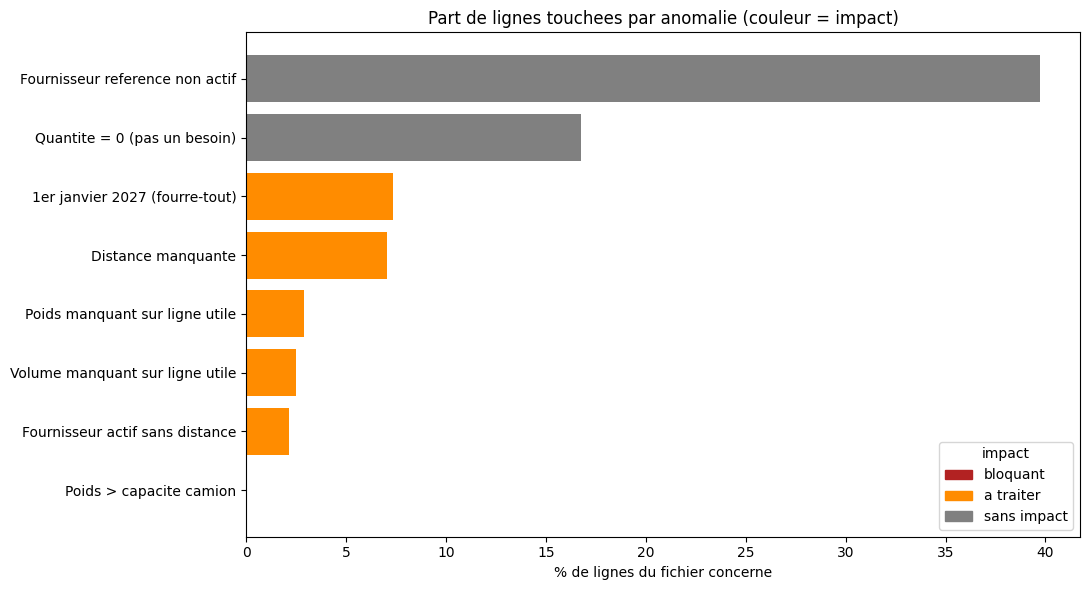

In [59]:
from matplotlib.patches import Patch

actif = bilan_final[bilan_final["nombre"] > 0].sort_values("pct")
couleurs = {"bloquant": "firebrick", "a traiter": "darkorange", "sans impact": "grey"}

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(actif["anomalie"], actif["pct"], color=actif["impact"].map(couleurs))
ax.set_title("Part de lignes touchees par anomalie (couleur = impact)")
ax.set_xlabel("% de lignes du fichier concerne")
ax.set_ylabel("")
legende = [Patch(color=c, label=l) for l, c in couleurs.items()]
ax.legend(handles=legende, title="impact")
plt.tight_layout()
plt.show()

**Notre constat :** visuellement, la barre la plus longue (quantité = 0, ~17 %) est **grise** : sans impact, nous l'excluons. Nos points orange (à traiter) restent sous ~7 %, et le seul point rouge (bloquant) est minuscule (0,03 %). Rien ne nous empêche d'avancer.

### 2.D.4 Le point de nos décisions

Voici **toutes** nos décisions pour le projet, regroupées par thème. Chacune renvoie à l'hypothèse (H) ou à la règle (R) qui la justifie (détail en 1.5 et 1.6).

**Périmètre des données**

| Notre décision | Pourquoi | Réf. |
|---|---|---|
| Nous excluons les lignes à quantité 0 | aucune pièce à transporter, leur volume fausserait le remplissage | H1 |
| Nous retirons le 1er janvier 2027 des analyses de charge | date fourre-tout confirmée par le client | H9 |
| Nous ne planifions pas la semaine de Noël | quasi vide : 3 lignes, toutes à quantité 0, donc aucun vrai besoin | H7 |

**Données manquantes**

| Notre décision | Pourquoi | Réf. |
|---|---|---|
| Poids et volumes manquants mis à 0 avec un indicateur, et camions concernés signalés | nous refusons d'inventer ; le chiffre reste honnête et se corrige à la source | H4 |
| Fournisseurs sans distance exclus du chiffrage mais gardés dans nos sorties | sans prix, pas d'optimisation ; enjeu négligeable (0,03 % du poids) | H6 |

**Calcul des camions**

| Notre décision | Pourquoi | Réf. |
|---|---|---|
| Un camion = un seul couple fournisseur x usine | règle du transporteur | R3 |
| Capacité 24 500 kg ou 110,4 m³, première limite atteinte | règle du transporteur | R2 |
| Une ligne plus lourde qu'un camion est scindée | sinon inchargeable | H3 |
| Une livraison peut être avancée de 7 jours max, jamais retardée | ne pas mettre l'usine en rupture | R1 |
| Un profil de livraison fixe par couple sur toute la période | simplicité et stabilité | H8 |

**Calcul du coût**

| Notre décision | Pourquoi | Réf. |
|---|---|---|
| `weight` pris comme poids total de la ligne | montré dans les données | H10 |
| Volume utilisé tel quel | il ne varie pas avec la quantité | H5 |
| Une distance unique par fournisseur | distance au point de consolidation | H11 |
| Distance arrondie à la tranche supérieure, moins de 30 km va en 30 | lecture de la grille | H2 |
| Tarif « >4000 » jusqu'à 24,5 t | confirmé par le client | H12 |
| Coût = grille x 3,3923 x 1,1943 | marge plus diesel | R5 |

## 3. Notre dictionnaire et notre cartographie des données

Avant de construire l'algorithme, nous voulons savoir précisément **ce que contient chaque donnée** et **à quoi elle nous sert**. Cette section est notre référence commune : pour chaque fichier, un tableau décrit chaque champ, sa qualité (ce que nous avons trouvé) et son rôle dans notre projet. Les exemples, min/max, nombres de valeurs distinctes et % de vides sont calculés depuis les données.

### 3.1 Dictionnaire de `released_schedule.csv`
Grain : **1 ligne = pièce x fournisseur x usine x quai x jour**.

In [60]:
def qualite_col(s):
    # resume de qualite calcule depuis les donnees
    pct_vide = s.isna().mean() * 100
    txt = str(s.nunique()) + " valeurs distinctes ; " + str(round(pct_vide, 2)) + " % vides"
    if pd.api.types.is_numeric_dtype(s):
        txt += " ; min " + str(s.min()) + " / max " + str(s.max())
    return txt

def exemple_col(s):
    v = s.dropna()
    return v.iloc[0] if len(v) else None

# description | unite | regle/domaine | role (notre connaissance metier)
meta = {
 "date":              ("Date limite du besoin", "date AAAA-MM-JJ", "jour ou le besoin doit etre couvert", "Date limite : nous pouvons avancer de 7 j max, jamais retarder (R1)"),
 "supplier_id":       ("Fournisseur expediteur", "code", "format SUP_ + 5 chiffres", "Cle de nos couples et lien vers les distances"),
 "material":          ("Reference de la piece", "code", "format MAT_ + 6 chiffres", "Contenu de nos camions (sortie 2)"),
 "plant":             ("Usine destinataire", "code", "format PLT_ + 3 chiffres", "Cle de nos couples"),
 "unloading_point":   ("Quai de dechargement", "code", "format ULP_ + 4 chiffres", "Information de livraison, pas une contrainte pour nous"),
 "schedule_quantity": ("Quantite de pieces demandee", "nombre de pieces", ">= 0", "Notre filtre des vrais besoins (> 0)"),
 "weight":            ("Poids total de la ligne", "kg", ">= 0, peut etre vide", "Remplissage des camions et colonne de la grille"),
 "volume":            ("Volume de la ligne", "m3", ">= 0, peut etre vide", "Controle de la capacite 110,4 m3"),
 "transmission_date": ("Date d'envoi du programme", "date AAAA-MM-JJ", "<= date du besoin", "Information que nous n'utilisons pas"),
 "version_date":      ("Version du planning", "date AAAA-MM-JJ", "1 seule valeur ici", "Controle de version"),
}
pos = schedule[schedule["schedule_quantity"] > 0]  # exemples pris sur de vrais besoins
lignes = []
for col, (desc, unite, regle, role) in meta.items():
    s = schedule[col]
    lignes.append({"Colonne": col, "Description": desc, "Type": str(s.dtype), "Unite": unite,
                   "Exemple": exemple_col(pos[col]), "Regles / domaine": regle,
                   "Qualite (ce que nous avons trouve)": qualite_col(s), "Role dans notre projet": role})
dico_planning = pd.DataFrame(lignes)
dico_planning

,Colonne,Description,Type,Unite,Exemple,Regles / domaine,Qualite (ce que nous avons trouve),Role dans notre projet
0,date,Date limite du besoin,object,date AAAA-MM-JJ,2026-11-11,jour ou le besoin doit etre couvert,35 valeurs distinctes ; 0.0 % vides,"Date limite : nous pouvons avancer de 7 j max,..."
1,supplier_id,Fournisseur expediteur,object,code,SUP_00091,format SUP_ + 5 chiffres,94 valeurs distinctes ; 0.0 % vides,Cle de nos couples et lien vers les distances
2,material,Reference de la piece,object,code,MAT_000110,format MAT_ + 6 chiffres,1229 valeurs distinctes ; 0.0 % vides,Contenu de nos camions (sortie 2)
3,plant,Usine destinataire,object,code,PLT_004,format PLT_ + 3 chiffres,4 valeurs distinctes ; 0.0 % vides,Cle de nos couples
4,unloading_point,Quai de dechargement,object,code,ULP_0050,format ULP_ + 4 chiffres,51 valeurs distinctes ; 0.0 % vides,"Information de livraison, pas une contrainte p..."
5,schedule_quantity,Quantite de pieces demandee,float64,nombre de pieces,5000.0,>= 0,399 valeurs distinctes ; 0.0 % vides ; min 0.0...,Notre filtre des vrais besoins (> 0)
6,weight,Poids total de la ligne,float64,kg,92.6,">= 0, peut etre vide",1746 valeurs distinctes ; 2.95 % vides ; min 0...,Remplissage des camions et colonne de la grille
7,volume,Volume de la ligne,float64,m3,0.4116,">= 0, peut etre vide",60 valeurs distinctes ; 2.57 % vides ; min 0.0...,"Controle de la capacite 110,4 m3"
8,transmission_date,Date d'envoi du programme,object,date AAAA-MM-JJ,2026-11-06,<= date du besoin,45 valeurs distinctes ; 0.0 % vides,Information que nous n'utilisons pas
9,version_date,Version du planning,object,date AAAA-MM-JJ,2026-11-08,1 seule valeur ici,1 valeurs distinctes ; 0.0 % vides,Controle de version


**Notre constat :** nos 10 colonnes sont claires. Nos piliers sont `supplier_id` + `plant` (nos couples), `schedule_quantity` (filtre des vrais besoins), `weight` et `volume` (remplissage et contrôle de capacité), et `date` (date limite avec marge de 7 jours). `unloading_point` et `transmission_date` ne sont pas des contraintes pour nous.

### 3.2 Dictionnaire de `distances.csv`
Grain : **1 ligne = 1 fournisseur**.

In [61]:
meta_d = {
 "supplier_id": ("Fournisseur", "code", "format SUP_ + 5 chiffres, unique", "Lien avec le planning"),
 "distance":    ("Distance au point de consolidation", "km", "> 0, peut etre vide", "Ligne de la grille tarifaire"),
}
lignes = []
for col, (desc, unite, regle, role) in meta_d.items():
    s = distances[col]
    lignes.append({"Colonne": col, "Description": desc, "Type": str(s.dtype), "Unite": unite,
                   "Exemple": exemple_col(s), "Regles / domaine": regle,
                   "Qualite (ce que nous avons trouve)": qualite_col(s), "Role dans notre projet": role})
dico_distances = pd.DataFrame(lignes)
dico_distances

,Colonne,Description,Type,Unite,Exemple,Regles / domaine,Qualite (ce que nous avons trouve),Role dans notre projet
0,supplier_id,Fournisseur,object,code,SUP_00001,"format SUP_ + 5 chiffres, unique",156 valeurs distinctes ; 0.0 % vides,Lien avec le planning
1,distance,Distance au point de consolidation,float64,km,47.0,"> 0, peut etre vide",85 valeurs distinctes ; 7.05 % vides ; min 6.0...,Ligne de la grille tarifaire


**Notre constat :** fichier simple et propre : un fournisseur, une distance (6 à 149 km). `distance` est notre entrée dans la grille tarifaire. Seules 11 distances manquent, dont 2 chez des fournisseurs actifs (traitées par H6).

### 3.3 Dictionnaire de `rate_sheet.pdf`
Grain : **1 case = tranche de distance x tranche de poids**. Nous décrivons sa structure et nos paramètres.

In [62]:
structure = [
 {"Element": "Lignes (tranches de distance)", "Unite": "km",
  "Contenu / valeur": ", ".join(map(str, grille.index))},
 {"Element": "Colonnes (tranches de poids)", "Unite": "kg",
  "Contenu / valeur": ", ".join(map(str, grille.columns))},
 {"Element": "Cout de base (case de la grille)", "Unite": "EUR",
  "Contenu / valeur": "de " + str(grille.min().min()) + " a " + str(grille.max().max())},
 {"Element": "Marge commerciale", "Unite": "coefficient",
  "Contenu / valeur": "x (1 + 2,3923) = x 3,3923"},
 {"Element": "Coefficient diesel", "Unite": "coefficient",
  "Contenu / valeur": "x 1,1943"},
 {"Element": "Prix final (notre formule)", "Unite": "EUR",
  "Contenu / valeur": "cout de base x 3,3923 x 1,1943"},
 {"Element": "Date de validite", "Unite": "date",
  "Contenu / valeur": "01/08/2026"},
]
dico_grille = pd.DataFrame(structure)
dico_grille

,Element,Unite,Contenu / valeur
0,Lignes (tranches de distance),km,"30, 50, 75, 100, 125, 150, 175, 200, 250, 300,..."
1,Colonnes (tranches de poids),kg,"50, 100, 200, 300, 400, 500, 750, 1000, 1500, ..."
2,Cout de base (case de la grille),EUR,de 4.75 a 325.25
3,Marge commerciale,coefficient,"x (1 + 2,3923) = x 3,3923"
4,Coefficient diesel,coefficient,"x 1,1943"
5,Prix final (notre formule),EUR,"cout de base x 3,3923 x 1,1943"
6,Date de validite,date,01/08/2026


**Notre constat :** la grille est une matrice distance x poids de coûts de base, à laquelle nous appliquons toujours marge (x 3,3923) et diesel (x 1,1943). Elle est valable depuis le 01/08/2026. C'est notre seule source de prix.

### 3.4 Notre cartographie des données
Comment nos trois fichiers s'assemblent pour produire un coût.

**Notre schéma**

Le diagramme ci-dessous montre comment nos trois fichiers s'assemblent pour produire le coût d'un envoi. Nous regroupons les besoins d'un couple fournisseur x usine sur un jour de livraison (poids et volume sommés) ; la distance choisit la ligne de la grille, le poids la colonne, et notre formule donne le coût.

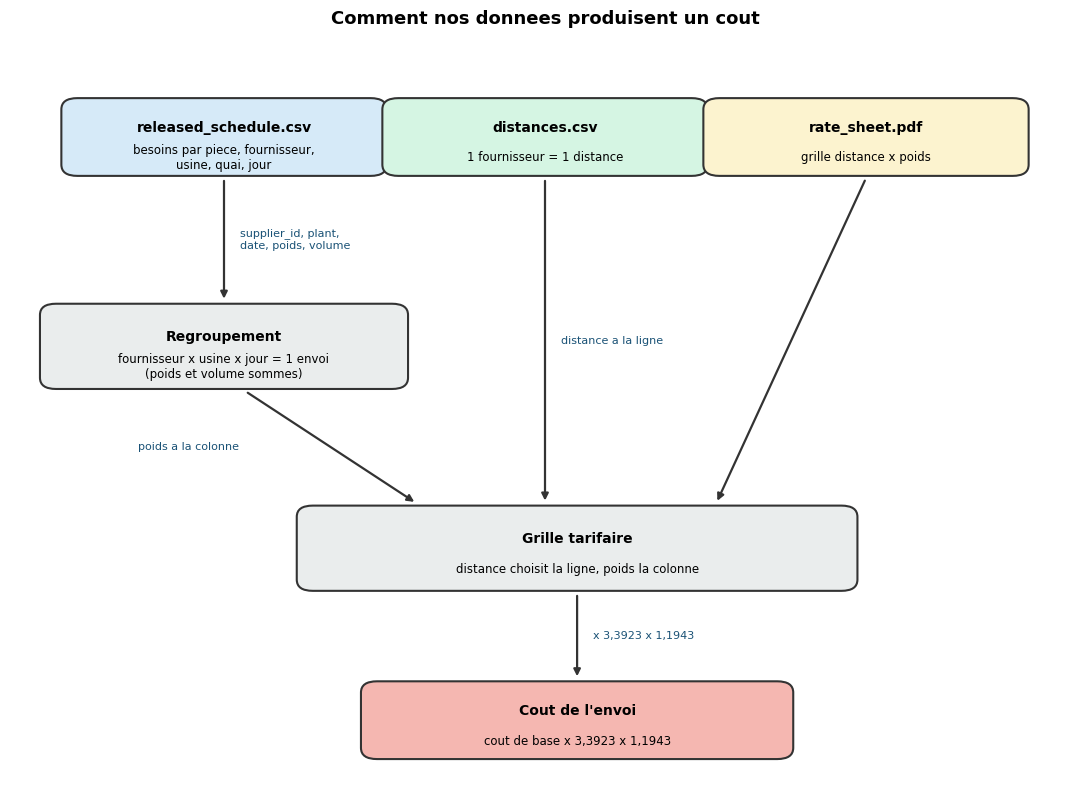

In [63]:
from matplotlib.patches import FancyBboxPatch

def boite(ax, x, y, w, h, titre, soustitre, couleur):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h,
                                boxstyle="round,pad=0.02,rounding_size=0.15",
                                linewidth=1.5, edgecolor="#333333", facecolor=couleur))
    ax.text(x, y + 0.12, titre, ha="center", va="center", fontsize=10, fontweight="bold")
    ax.text(x, y - 0.28, soustitre, ha="center", va="center", fontsize=8.5)

def fleche(ax, p1, p2, label="", dx=0.15):
    ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#333333"))
    if label:
        mx, my = (p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2
        ax.text(mx + dx, my, label, ha="left", va="center", fontsize=8, color="#1a5276")

fig, ax = plt.subplots(figsize=(11, 8))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")

boite(ax, 2, 8.6, 3.0, 1.0, "released_schedule.csv", "besoins par piece, fournisseur,\nusine, quai, jour", "#d6eaf8")
boite(ax, 5, 8.6, 3.0, 1.0, "distances.csv", "1 fournisseur = 1 distance", "#d5f5e3")
boite(ax, 8, 8.6, 3.0, 1.0, "rate_sheet.pdf", "grille distance x poids", "#fcf3cf")

boite(ax, 2, 5.8, 3.4, 1.1, "Regroupement", "fournisseur x usine x jour = 1 envoi\n(poids et volume sommes)", "#eaeded")
boite(ax, 5.3, 3.1, 5.2, 1.1, "Grille tarifaire", "distance choisit la ligne, poids la colonne", "#eaeded")
boite(ax, 5.3, 0.8, 4.0, 1.0, "Cout de l'envoi", "cout de base x 3,3923 x 1,1943", "#f5b7b1")

fleche(ax, (2, 8.05), (2, 6.4), "supplier_id, plant,\ndate, poids, volume")
fleche(ax, (2.2, 5.2), (3.8, 3.7), "poids a la colonne", dx=-1.8)
fleche(ax, (5, 8.05), (5.0, 3.7), "distance a la ligne")
fleche(ax, (8, 8.05), (6.6, 3.7), "", dx=0)
fleche(ax, (5.3, 2.5), (5.3, 1.35), "x 3,3923 x 1,1943")

ax.set_title("Comment nos donnees produisent un cout", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Schéma relationnel de nos données** : comme un schéma de base de données, chaque fichier est une table avec sa clé primaire (PK, en gras) et ses liens (FK, en italique). Les cardinalités (n, 1) montrent le sens des relations. Sous le schéma, nous affichons la couverture réelle calculée depuis les fichiers.

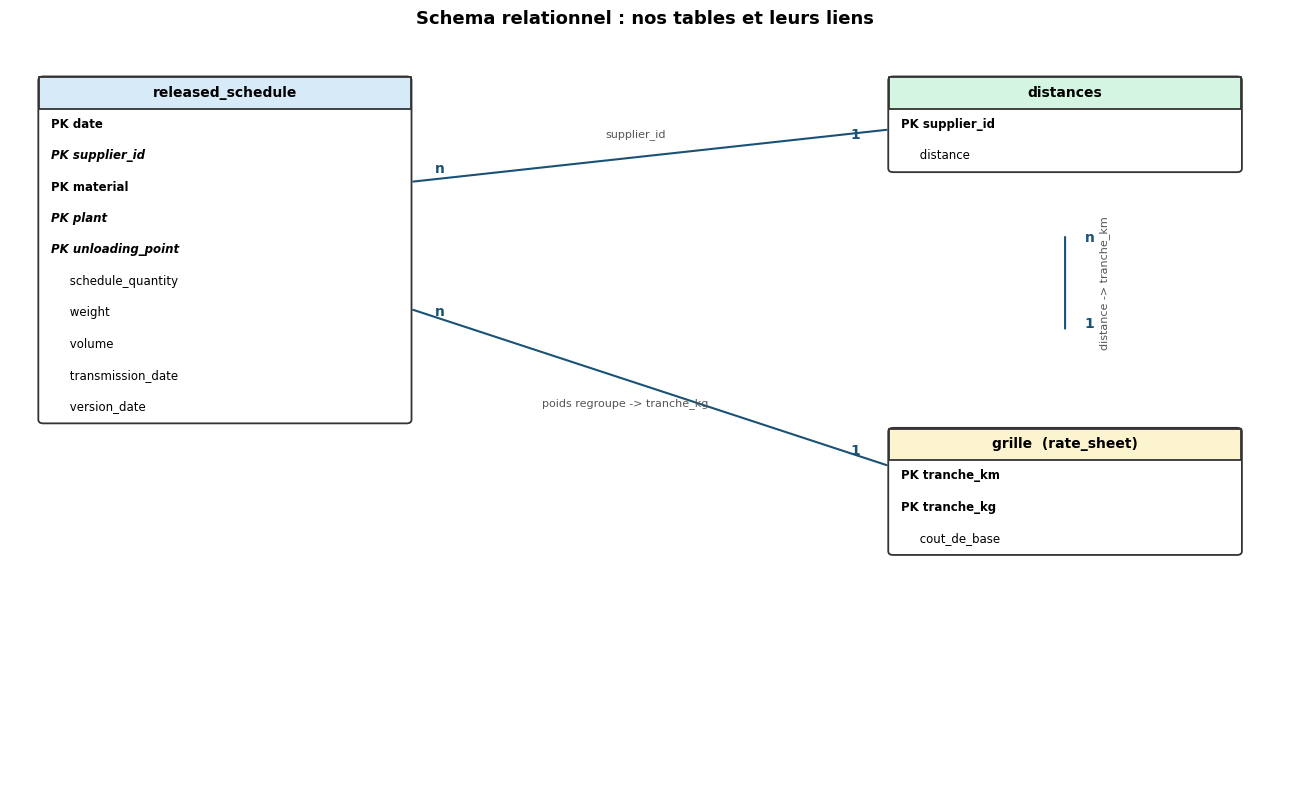

Couverture (calculee depuis les fichiers) :
  planning.supplier_id -> distances : 94 / 94 fournisseurs actifs couverts  (n:1)
  fournisseur x usine               : 185 couples au total, 181 actifs  (n:n)
  unloading_point -> plant          : chaque quai depend de 1 usine  (1:n)


In [64]:
from matplotlib.patches import FancyBboxPatch, Rectangle

# --- couverture reelle, calculee depuis les fichiers ---
pos = schedule[schedule["schedule_quantity"] > 0]
f_actifs = set(pos["supplier_id"].unique())
couples_total = schedule.groupby(["supplier_id", "plant"]).ngroups
couples_actifs = pos.groupby(["supplier_id", "plant"]).ngroups
couverts = len(f_actifs & set(distances["supplier_id"]))
quai_une_usine = int(schedule.groupby("unloading_point")["plant"].nunique().max())

def table_box(ax, x, y, w, titre, champs, couleur):
    """Dessine une table facon schema SQL : titre, colonnes (PK en gras, FK en italique)."""
    hl = 0.42
    h = hl * (len(champs) + 1)
    ax.add_patch(FancyBboxPatch((x, y - h), w, h, boxstyle="round,pad=0.01,rounding_size=0.05",
                                linewidth=1.3, edgecolor="#333", facecolor="white", zorder=2))
    ax.add_patch(Rectangle((x, y - hl), w, hl, facecolor=couleur, edgecolor="#333", linewidth=1.3, zorder=3))
    ax.text(x + w / 2, y - hl / 2, titre, ha="center", va="center", fontsize=10, fontweight="bold", zorder=4)
    for i, (nom, pk, fk) in enumerate(champs):
        yy = y - hl * (i + 1) - hl / 2
        prefixe = "PK " if pk else ("FK " if fk else "     ")
        ax.text(x + 0.12, yy, prefixe + nom, ha="left", va="center", fontsize=8.5,
                fontweight=("bold" if pk else "normal"), style=("italic" if fk else "normal"), zorder=4)

fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 13); ax.set_ylim(0, 10); ax.axis("off")

table_box(ax, 0.3, 9.4, 3.8, "released_schedule",
          [("date", 1, 0), ("supplier_id", 1, 1), ("material", 1, 0), ("plant", 1, 1),
           ("unloading_point", 1, 1), ("schedule_quantity", 0, 0), ("weight", 0, 0),
           ("volume", 0, 0), ("transmission_date", 0, 0), ("version_date", 0, 0)], "#d6eaf8")
table_box(ax, 9.0, 9.4, 3.6, "distances", [("supplier_id", 1, 0), ("distance", 0, 0)], "#d5f5e3")
table_box(ax, 9.0, 4.7, 3.6, "grille  (rate_sheet)",
          [("tranche_km", 1, 0), ("tranche_kg", 1, 0), ("cout_de_base", 0, 0)], "#fcf3cf")

def lien(p1, p2):
    ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="-", lw=1.5, color="#1a5276"), zorder=1)

# released_schedule.supplier_id -> distances.supplier_id
lien((4.1, 8.0), (9.0, 8.7))
ax.text(4.35, 8.12, "n", color="#1a5276", fontsize=10, fontweight="bold")
ax.text(8.6, 8.58, "1", color="#1a5276", fontsize=10, fontweight="bold")
ax.text(6.4, 8.6, "supplier_id", color="#555", fontsize=8, ha="center")

# distances.distance -> grille.tranche_km
lien((10.8, 7.3), (10.8, 6.0))
ax.text(11.0, 7.2, "n", color="#1a5276", fontsize=10, fontweight="bold")
ax.text(11.0, 6.05, "1", color="#1a5276", fontsize=10, fontweight="bold")
ax.text(11.15, 6.65, "distance -> tranche_km", color="#555", fontsize=8, rotation=90, va="center")

# released_schedule (poids regroupe) -> grille.tranche_kg
lien((4.1, 6.3), (9.0, 4.2))
ax.text(4.35, 6.2, "n", color="#1a5276", fontsize=10, fontweight="bold")
ax.text(8.6, 4.35, "1", color="#1a5276", fontsize=10, fontweight="bold")
ax.text(6.3, 5.0, "poids regroupe -> tranche_kg", color="#555", fontsize=8, ha="center")

ax.set_title("Schema relationnel : nos tables et leurs liens", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Couverture (calculee depuis les fichiers) :")
print("  planning.supplier_id -> distances :", couverts, "/", len(f_actifs), "fournisseurs actifs couverts  (n:1)")
print("  fournisseur x usine               :", couples_total, "couples au total,", couples_actifs, "actifs  (n:n)")
print("  unloading_point -> plant          : chaque quai depend de", quai_une_usine, "usine  (1:n)")

**Notre constat :** nos clés relient bien les fichiers : `supplier_id` connecte le planning aux distances (100 % des fournisseurs actifs couverts), et les tranches de distance/poids connectent nos envois à la grille. Chaque quai appartient à une seule usine. Nos **181 couples actifs** sont l'unité de base de notre travail.

### Notre conclusion de la section 3

Nos trois fichiers s'assemblent simplement : le planning donne les besoins, que nous regroupons par couple fournisseur x usine et par jour pour former des envois ; la distance et le poids de l'envoi pointent une case de la grille, et notre formule (x 3,3923 x 1,1943) en donne le coût. Tout tient par `supplier_id` et par les tranches de distance et de poids.

Les limites que nous connaissons (poids et volumes inconnus, fournisseurs sans distance, 1er janvier) sont déjà tranchées dans nos décisions (2.D.4). Nos données sont prêtes pour construire l'algorithme.

## 4. Notre pipeline de préparation

Notre pipeline transforme les 3 fichiers bruts en une base propre, **une ligne par vrai besoin**. Il nettoie, complète et marque, mais ne prend **aucune décision d'optimisation** (ce sera le rôle de notre algorithme au milestone 3). Nous l'écrivons en petites fonctions pour le réutiliser tel quel au milestone 5 (fichiers `.py`, `main.py`, Streamlit).

Point important : le pipeline doit tourner sur un **nouveau fichier que nous ne connaissons pas encore**. Nos contrôles ne dépendent donc jamais de nos chiffres actuels, seulement de règles **toujours vraies**.

### 4.0 Nos paramètres
Tous nos paramètres sont ici, et nulle part en dur dans le code. Pour changer une règle (nouvelle date fourre-tout, nouvelle marge), nous ne touchons qu'à cette cellule.

In [66]:
PARAMETRES = {
    # chemins (relatifs au dossier du notebook)
    "chemin_planning":  "../data/released_schedule.csv",
    "chemin_distances": "../data/distances.csv",
    "chemin_grille":    "../docs/rate_sheet.pdf",
    "dossier_sortie":   "../data/processed/",
    # capacites d'un camion (R2)
    "CAP_POIDS":  24500.0,   # kg
    "CAP_VOLUME": 110.4,     # m3
    # tarification (R5)
    "MARGE":  2.3923,
    "DIESEL": 1.1943,
    # dates "fourre-tout" a retirer (H9) ; liste, pour en ajouter si besoin
    "DATES_FOURRE_TOUT": ["2027-01-01"],
    # tranches de distance de la grille (au-dela : ">650") (H2)
    "TRANCHES_KM": [30, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400, 500, 650],
    # colonnes attendues dans les fichiers recus
    "COLONNES_PLANNING":  ["date", "supplier_id", "material", "plant", "unloading_point",
                            "schedule_quantity", "weight", "volume", "transmission_date", "version_date"],
    "COLONNES_DISTANCES": ["supplier_id", "distance"],
}
print("Parametres charges :", len(PARAMETRES), "cles")

Parametres charges : 12 cles


### 4.1 Charger
Nous lisons les 3 fichiers bruts (planning en `utf-8-sig`, distances, et la grille depuis le PDF).

In [67]:
def charger_fichiers(p):
    """Lit le planning, les distances et la grille tarifaire du PDF."""
    planning = pd.read_csv(p["chemin_planning"], encoding="utf-8-sig")
    distances = pd.read_csv(p["chemin_distances"])
    with pdfplumber.open(p["chemin_grille"]) as pdf:
        tableau = pdf.pages[0].extract_tables()[0]
    grille = pd.DataFrame(tableau[1:], columns=tableau[0]).set_index(tableau[0][0])
    grille = grille.apply(lambda col: col.map(lambda x: float(str(x).replace(",", "."))))
    return planning, distances, grille

planning_brut, distances_brut, grille_brute = charger_fichiers(PARAMETRES)
print("Planning :", planning_brut.shape, "| Distances :", distances_brut.shape, "| Grille :", grille_brute.shape)

Planning : (5728, 10) | Distances : (156, 2) | Grille : (14, 15)


### 4.2 Vérifier les fichiers reçus
Avant tout traitement, nous vérifions que le fichier est exploitable. Les contrôles **bloquants** arrêtent le pipeline avec un message qui dit quoi corriger. Les **alertes** sont affichées mais ne bloquent pas (nous savons déjà les traiter : H4, H6, H3).

In [68]:
def verifier_entree(planning, distances, grille, p):
    """Controle les fichiers recus ; bloque si une regle toujours vraie est violee."""
    erreurs = []
    # colonnes attendues presentes
    manque_p = [c for c in p["COLONNES_PLANNING"] if c not in planning.columns]
    manque_d = [c for c in p["COLONNES_DISTANCES"] if c not in distances.columns]
    if manque_p:
        erreurs.append("colonnes manquantes dans le planning : " + str(manque_p))
    if manque_d:
        erreurs.append("colonnes manquantes dans les distances : " + str(manque_d))
    # valeurs numeriques convertibles (pas de texte la ou on attend un nombre)
    for col in ["schedule_quantity", "weight", "volume"]:
        if col in planning.columns:
            nb_casse = pd.to_numeric(planning[col], errors="coerce").isna().sum() - planning[col].isna().sum()
            if nb_casse > 0:
                erreurs.append("valeurs non numeriques dans " + col)
    if "distance" in distances.columns:
        nb_casse = pd.to_numeric(distances["distance"], errors="coerce").isna().sum() - distances["distance"].isna().sum()
        if nb_casse > 0:
            erreurs.append("valeurs non numeriques dans distance")
    # dates convertibles
    nb_casse = pd.to_datetime(planning["date"], errors="coerce").isna().sum() - planning["date"].isna().sum()
    if nb_casse > 0:
        erreurs.append("dates non convertibles dans date")
    # aucune valeur negative
    for col in ["schedule_quantity", "weight", "volume"]:
        if col in planning.columns and (pd.to_numeric(planning[col], errors="coerce") < 0).any():
            erreurs.append("valeurs negatives dans " + col)
    if "distance" in distances.columns and (pd.to_numeric(distances["distance"], errors="coerce") < 0).any():
        erreurs.append("distances negatives")
    # aucun doublon sur la cle
    cle = ["date", "supplier_id", "material", "plant", "unloading_point"]
    if planning.duplicated(subset=cle).any():
        erreurs.append("doublons sur la cle " + str(cle))
    # grille complete et numerique
    if grille.isna().any().any():
        erreurs.append("la grille contient des cases vides ou non numeriques")

    if erreurs:
        raise ValueError("Pipeline arrete, fichier a corriger :\n- " + "\n- ".join(erreurs))

    # alertes non bloquantes
    actifs = set(planning.loc[pd.to_numeric(planning["schedule_quantity"], errors="coerce") > 0, "supplier_id"])
    avec_dist = set(distances.loc[distances["distance"].notna(), "supplier_id"])
    print("Controles bloquants : tous OK")
    print("ALERTE poids vides        :", int(planning["weight"].isna().sum()))
    print("ALERTE volumes vides      :", int(planning["volume"].isna().sum()))
    print("ALERTE fournisseurs actifs sans distance :", len(actifs - avec_dist))
    print("ALERTE lignes plus lourdes qu'un camion  :", int((pd.to_numeric(planning["weight"], errors="coerce") > p["CAP_POIDS"]).sum()))

verifier_entree(planning_brut, distances_brut, grille_brute, PARAMETRES)

Controles bloquants : tous OK
ALERTE poids vides        : 169
ALERTE volumes vides      : 147
ALERTE fournisseurs actifs sans distance : 2
ALERTE lignes plus lourdes qu'un camion  : 2


### 4.3 Retirer
Nous retirons les lignes à **quantité 0** (H1 : aucune pièce à transporter) et les lignes des **dates fourre-tout** (H9 : confirmé par le client).

In [69]:
def retirer_lignes(planning, p):
    """Retire les lignes a quantite 0 (H1) et les dates fourre-tout (H9)."""
    q = pd.to_numeric(planning["schedule_quantity"], errors="coerce")
    sans_zero = planning[q > 0].copy()
    propre = sans_zero[~sans_zero["date"].astype(str).isin(p["DATES_FOURRE_TOUT"])].copy()
    return propre

apres_retrait = retirer_lignes(planning_brut, PARAMETRES)
print("Avant :", len(planning_brut), "| apres retrait :", len(apres_retrait))

Avant : 5728 | apres retrait : 4390


### 4.4 Compléter
Nous mettons à 0 les poids et volumes vides, et nous créons les colonnes `poids_manquant` / `volume_manquant` (H4). Nous n'inventons aucune valeur : le marquage garde la trace.

In [70]:
def completer(df):
    """Met a 0 les poids/volumes vides et marque les lignes completees (H4)."""
    df = df.copy()
    df["poids_manquant"] = df["weight"].isna()
    df["volume_manquant"] = df["volume"].isna()
    df["weight"] = df["weight"].fillna(0.0)
    df["volume"] = df["volume"].fillna(0.0)
    return df

apres_completion = completer(apres_retrait)
print("Poids completes :", int(apres_completion["poids_manquant"].sum()),
      "| Volumes completes :", int(apres_completion["volume_manquant"].sum()))

Poids completes : 134 | Volumes completes : 116


### 4.5 Enrichir
Nous ajoutons les colonnes dont l'algorithme aura besoin : `semaine` et `jour`, la `distance` (jointure sur `supplier_id`), la `ligne_grille` (tranche supérieure, moins de 30 km va en 30 ; H2/H11), et les marqueurs `sans_distance` (H6) et `ligne_trop_lourde` (poids > CAP_POIDS ; H3).

In [71]:
def tranche_grille(km, tranches):
    """Renvoie la ligne de grille (tranche superieure) pour une distance."""
    if pd.isna(km):
        return None
    for t in tranches:
        if km <= t:
            return str(t)
    return ">650"

def enrichir(df, distances, p):
    """Ajoute date, semaine, jour, distance, ligne_grille et les marqueurs H3/H6."""
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["semaine"] = df["date"].dt.to_period("W").dt.start_time
    noms_jours = {0: "lundi", 1: "mardi", 2: "mercredi", 3: "jeudi", 4: "vendredi", 5: "samedi", 6: "dimanche"}
    df["jour"] = df["date"].dt.weekday.map(noms_jours)
    df = df.merge(distances[["supplier_id", "distance"]], on="supplier_id", how="left")
    df["ligne_grille"] = df["distance"].apply(lambda km: tranche_grille(km, p["TRANCHES_KM"]))
    df["sans_distance"] = df["distance"].isna()
    df["ligne_trop_lourde"] = df["weight"] > p["CAP_POIDS"]
    return df

apres_enrichissement = enrichir(apres_completion, distances_brut, PARAMETRES)
print("Colonnes ajoutees :", [c for c in apres_enrichissement.columns if c not in planning_brut.columns])
print("Sans distance :", int(apres_enrichissement["sans_distance"].sum()),
      "| Trop lourdes :", int(apres_enrichissement["ligne_trop_lourde"].sum()))

Colonnes ajoutees : ['poids_manquant', 'volume_manquant', 'semaine', 'jour', 'distance', 'ligne_grille', 'sans_distance', 'ligne_trop_lourde']
Sans distance : 4 | Trop lourdes : 1


### 4.6 Préparer la grille
Nous passons des coûts de base aux **prix finaux** = coût x (1 + MARGE) x DIESEL (R5).

In [72]:
def preparer_grille(grille, p):
    """Renvoie la grille des prix finaux = cout x (1 + MARGE) x DIESEL (R5)."""
    return grille * (1 + p["MARGE"]) * p["DIESEL"]

grille_prix_test = preparer_grille(grille_brute, PARAMETRES)
print("Exemple 300 km / 1000 kg :", round(float(grille_prix_test.loc["300", "1000"]), 2), "EUR")

Exemple 300 km / 1000 kg : 335.34 EUR


### 4.7 Vérifier le résultat
Nous contrôlons la sortie avec des règles **toujours vraies** (jamais nos chiffres du jour). Chaque contrôle s'affiche OK ou ECHEC.

In [73]:
def verifier_sortie(n_entree, n_retirees, propre, grille_prix, p):
    """Verifie la sortie avec des regles toujours vraies ; affiche OK/ECHEC."""
    q = pd.to_numeric(propre["schedule_quantity"], errors="coerce")
    dates_str = pd.to_datetime(propre["date"]).dt.strftime("%Y-%m-%d")
    controles = {
        "plus aucune quantite a 0": bool((q > 0).all()),
        "plus aucune date fourre-tout": bool((~dates_str.isin(p["DATES_FOURRE_TOUT"])).all()),
        "plus aucun poids/volume vide": bool(propre["weight"].notna().all() and propre["volume"].notna().all()),
        "lignes entree = sortie + retirees": n_entree == len(propre) + n_retirees,
        "ligne_grille presente sauf sans_distance": bool((propre["ligne_grille"].notna() | propre["sans_distance"]).all()),
        "exemple grille 300km/1000kg = 335,34": round(float(grille_prix.loc["300", "1000"]), 2) == 335.34,
    }
    for libelle, ok in controles.items():
        print(("OK    " if ok else "ECHEC ") + "- " + libelle)
    return all(controles.values())

_ok = verifier_sortie(len(planning_brut), len(planning_brut) - len(apres_enrichissement),
                      apres_enrichissement, grille_prix_test, PARAMETRES)
print("Tous les controles passent :", _ok)

OK    - plus aucune quantite a 0
OK    - plus aucune date fourre-tout
OK    - plus aucun poids/volume vide
OK    - lignes entree = sortie + retirees
OK    - ligne_grille presente sauf sans_distance
OK    - exemple grille 300km/1000kg = 335,34
Tous les controles passent : True


### 4.8 Enregistrer
Nous enregistrons 3 fichiers dans `../data/processed/`. Nous **trions** les lignes pour que la sortie soit toujours dans le même ordre (reproductible).

In [74]:
import os

def exporter(propre, grille_prix, journal, p):
    """Cree le dossier de sortie et enregistre les 3 fichiers, dans un ordre stable."""
    os.makedirs(p["dossier_sortie"], exist_ok=True)
    tri = ["date", "supplier_id", "plant", "material", "unloading_point"]
    propre = propre.sort_values(tri).reset_index(drop=True)
    propre.to_csv(p["dossier_sortie"] + "planning_propre.csv", index=False)
    grille_prix.to_csv(p["dossier_sortie"] + "grille_prix.csv")
    journal.to_csv(p["dossier_sortie"] + "journal_pipeline.csv", index=False)
    return propre

print("Fonction exporter() prete.")

Fonction exporter() prete.


### 4.9 Notre pipeline complet
Une seule fonction enchaîne les 8 étapes et renvoie `(planning_propre, grille_prix, journal)`. Le **journal** résume le parcours : étape, lignes avant, lignes après, lignes retirées ou marquées, et la règle appliquée.

In [75]:
def preparer_donnees(p):
    """Enchaine nos 8 etapes et renvoie (planning_propre, grille_prix, journal)."""
    planning, distances, grille = charger_fichiers(p)
    verifier_entree(planning, distances, grille, p)

    n_brut = len(planning)
    q = pd.to_numeric(planning["schedule_quantity"], errors="coerce")
    apres_zero = planning[q > 0].copy()
    apres_ft = apres_zero[~apres_zero["date"].astype(str).isin(p["DATES_FOURRE_TOUT"])].copy()
    n0, nft = len(apres_zero), len(apres_ft)

    propre = completer(apres_ft)
    propre = enrichir(propre, distances, p)
    grille_prix = preparer_grille(grille, p)

    journal = pd.DataFrame([
        {"etape": "charger",                    "lignes_avant": n_brut, "lignes_apres": n_brut, "retirees_ou_marquees": 0,                                                     "regle": "-"},
        {"etape": "retirer quantite 0",         "lignes_avant": n_brut, "lignes_apres": n0,     "retirees_ou_marquees": n_brut - n0,                                           "regle": "H1"},
        {"etape": "retirer dates fourre-tout",  "lignes_avant": n0,     "lignes_apres": nft,    "retirees_ou_marquees": n0 - nft,                                              "regle": "H9"},
        {"etape": "completer poids/volume",     "lignes_avant": nft,    "lignes_apres": nft,    "retirees_ou_marquees": int(propre["poids_manquant"].sum() + propre["volume_manquant"].sum()), "regle": "H4"},
        {"etape": "enrichir",                   "lignes_avant": nft,    "lignes_apres": len(propre), "retirees_ou_marquees": int(propre["sans_distance"].sum() + propre["ligne_trop_lourde"].sum()), "regle": "H2/H3/H6/H11"},
    ])

    verifier_sortie(n_brut, n_brut - nft, propre, grille_prix, p)
    propre = exporter(propre, grille_prix, journal, p)
    return propre, grille_prix, journal

planning_propre, grille_prix, journal = preparer_donnees(PARAMETRES)
journal

Controles bloquants : tous OK
ALERTE poids vides        : 169
ALERTE volumes vides      : 147
ALERTE fournisseurs actifs sans distance : 2
ALERTE lignes plus lourdes qu'un camion  : 2


OK    - plus aucune quantite a 0
OK    - plus aucune date fourre-tout
OK    - plus aucun poids/volume vide
OK    - lignes entree = sortie + retirees
OK    - ligne_grille presente sauf sans_distance
OK    - exemple grille 300km/1000kg = 335,34


,etape,lignes_avant,lignes_apres,retirees_ou_marquees,regle
0,charger,5728,5728,0,-
1,retirer quantite 0,5728,4769,959,H1
2,retirer dates fourre-tout,4769,4390,379,H9
3,completer poids/volume,4390,4390,250,H4
4,enrichir,4390,4390,5,H2/H3/H6/H11


### 4.10 Reproductibilité
Nous lançons le pipeline deux fois et nous vérifions que les deux résultats sont strictement identiques.

In [76]:
p1, g1, j1 = preparer_donnees(PARAMETRES)
p2, g2, j2 = preparer_donnees(PARAMETRES)
identique = p1.equals(p2) and g1.equals(g2) and j1.equals(j2)
print("Reproductible :", "OUI" if identique else "NON")

Controles bloquants : tous OK
ALERTE poids vides        : 169
ALERTE volumes vides      : 147
ALERTE fournisseurs actifs sans distance : 2
ALERTE lignes plus lourdes qu'un camion  : 2


OK    - plus aucune quantite a 0
OK    - plus aucune date fourre-tout
OK    - plus aucun poids/volume vide
OK    - lignes entree = sortie + retirees
OK    - ligne_grille presente sauf sans_distance
OK    - exemple grille 300km/1000kg = 335,34
Controles bloquants : tous OK
ALERTE poids vides        : 169
ALERTE volumes vides      : 147
ALERTE fournisseurs actifs sans distance : 2
ALERTE lignes plus lourdes qu'un camion  : 2
OK    - plus aucune quantite a 0
OK    - plus aucune date fourre-tout
OK    - plus aucun poids/volume vide
OK    - lignes entree = sortie + retirees
OK    - ligne_grille presente sauf sans_distance
OK    - exemple grille 300km/1000kg = 335,34
Reproductible : OUI


### 4.11 Notre visualisation du pipeline
Deux vues simples : l'**entonnoir** (combien de lignes à chaque étape) et **ce que nous avons marqué**.

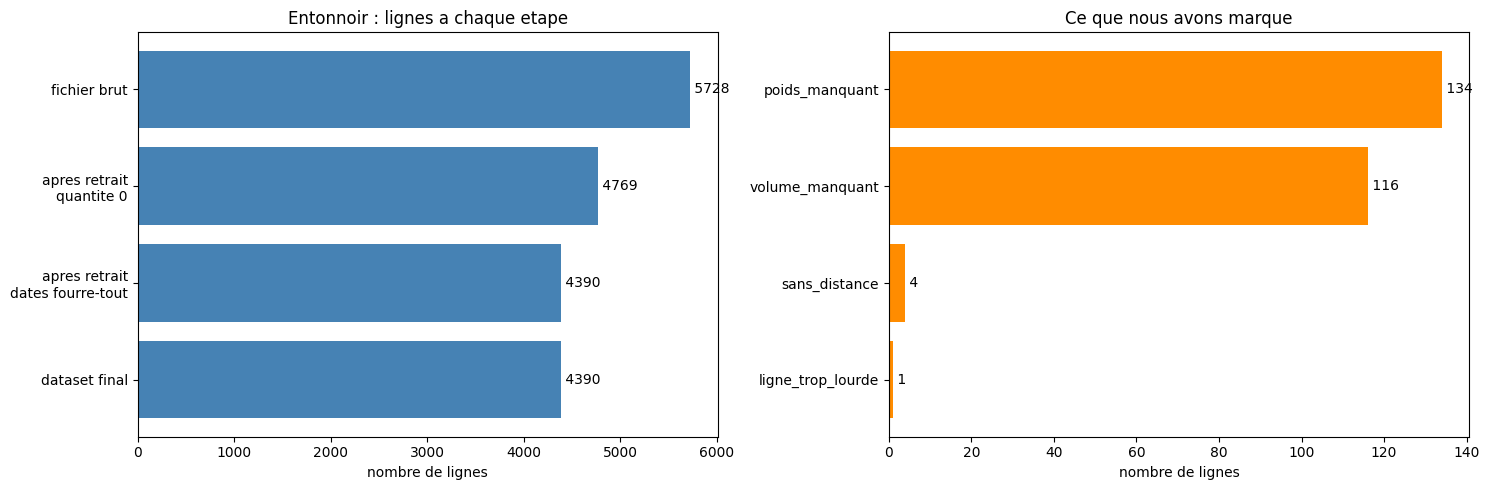

In [77]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Entonnoir : lignes a chaque etape
etapes = ["fichier brut", "apres retrait\nquantite 0", "apres retrait\ndates fourre-tout", "dataset final"]
valeurs = [journal.loc[0, "lignes_avant"], journal.loc[1, "lignes_apres"],
           journal.loc[2, "lignes_apres"], len(planning_propre)]
ax1.barh(range(len(etapes)), valeurs, color="steelblue")
ax1.set_yticks(range(len(etapes))); ax1.set_yticklabels(etapes)
ax1.invert_yaxis()
ax1.set_title("Entonnoir : lignes a chaque etape")
ax1.set_xlabel("nombre de lignes")
for i, v in enumerate(valeurs):
    ax1.text(v, i, " " + str(v), va="center")

# Ce que nous avons marque
marqueurs = ["poids_manquant", "volume_manquant", "sans_distance", "ligne_trop_lourde"]
compte = [int(planning_propre[m].sum()) for m in marqueurs]
ax2.barh(marqueurs, compte, color="darkorange")
ax2.invert_yaxis()
ax2.set_title("Ce que nous avons marque")
ax2.set_xlabel("nombre de lignes")
for i, v in enumerate(compte):
    ax2.text(v, i, " " + str(v), va="center")

plt.tight_layout()
plt.show()

## 5. Notre dataset consolidé

Voici la base que produit notre pipeline : `planning_propre`, une ligne par vrai besoin, prête pour la suite.

### 5.1 Aperçu
Les 5 premières lignes de notre dataset.

In [78]:
planning_propre.head()

,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date,poids_manquant,volume_manquant,semaine,jour,distance,ligne_grille,sans_distance,ligne_trop_lourde
0,2026-11-09,SUP_00011,MAT_000844,PLT_002,ULP_0022,1000.0,125.8,0.8868,2026-11-04,2026-11-08,False,False,2026-11-09,lundi,145.0,150,False,False
1,2026-11-09,SUP_00011,MAT_000120,PLT_004,ULP_0050,1000.0,125.8,0.8868,2026-11-06,2026-11-08,False,False,2026-11-09,lundi,145.0,150,False,False
2,2026-11-09,SUP_00011,MAT_000412,PLT_004,ULP_0050,1500.0,120.0,0.5700,2026-11-06,2026-11-08,False,False,2026-11-09,lundi,145.0,150,False,False
3,2026-11-09,SUP_00011,MAT_000638,PLT_004,ULP_0050,2500.0,146.8,0.8868,2026-11-06,2026-11-08,False,False,2026-11-09,lundi,145.0,150,False,False
4,2026-11-09,SUP_00011,MAT_000940,PLT_004,ULP_0050,2500.0,129.3,0.8868,2026-11-06,2026-11-08,False,False,2026-11-09,lundi,145.0,150,False,False


**Notre constat :** chaque ligne est un vrai besoin, enrichi de la semaine, du jour, de la distance, de la ligne de grille et de nos marqueurs. C'est le format que notre algorithme consommera.

### 5.2 Description des colonnes
Pour chaque colonne : type, description, et origine (fichier brut ou ajoutée par nous, avec l'étape).

In [79]:
infos = {
 "date":              ("date limite du besoin", "brut (released_schedule)"),
 "supplier_id":       ("fournisseur", "brut (released_schedule)"),
 "material":          ("reference de la piece", "brut (released_schedule)"),
 "plant":             ("usine destinataire", "brut (released_schedule)"),
 "unloading_point":   ("quai de dechargement", "brut (released_schedule)"),
 "schedule_quantity": ("quantite demandee", "brut (released_schedule)"),
 "weight":            ("poids total de la ligne (kg)", "brut, complete a l'etape 4.4"),
 "volume":            ("volume de la ligne (m3)", "brut, complete a l'etape 4.4"),
 "transmission_date": ("date d'envoi du programme", "brut (released_schedule)"),
 "version_date":      ("version du planning", "brut (released_schedule)"),
 "poids_manquant":    ("poids absent a l'origine", "ajoutee par nous (4.4)"),
 "volume_manquant":   ("volume absent a l'origine", "ajoutee par nous (4.4)"),
 "semaine":           ("lundi de la semaine du besoin", "ajoutee par nous (4.5)"),
 "jour":              ("jour de la semaine", "ajoutee par nous (4.5)"),
 "distance":          ("distance au point de consolidation (km)", "ajoutee par nous (4.5, depuis distances)"),
 "ligne_grille":      ("tranche de distance de la grille", "ajoutee par nous (4.5)"),
 "sans_distance":     ("fournisseur sans distance connue", "ajoutee par nous (4.5)"),
 "ligne_trop_lourde": ("poids superieur a un camion", "ajoutee par nous (4.5)"),
}
description = pd.DataFrame(
    [{"Colonne": c, "Type": str(planning_propre[c].dtype), "Description": d, "Origine": o}
     for c, (d, o) in infos.items() if c in planning_propre.columns]
)
description

,Colonne,Type,Description,Origine
0,date,datetime64[ns],date limite du besoin,brut (released_schedule)
1,supplier_id,object,fournisseur,brut (released_schedule)
2,material,object,reference de la piece,brut (released_schedule)
3,plant,object,usine destinataire,brut (released_schedule)
4,unloading_point,object,quai de dechargement,brut (released_schedule)
5,schedule_quantity,float64,quantite demandee,brut (released_schedule)
6,weight,float64,poids total de la ligne (kg),"brut, complete a l'etape 4.4"
7,volume,float64,volume de la ligne (m3),"brut, complete a l'etape 4.4"
8,transmission_date,object,date d'envoi du programme,brut (released_schedule)
9,version_date,object,version du planning,brut (released_schedule)


**Notre constat :** nous gardons les **noms d'origine** des colonnes brutes et nous nommons en français les **8 colonnes que nous ajoutons**. Chacune a un rôle clair pour le milestone 3.

### 5.3 Nos chiffres clés
Les grandeurs qui décrivent notre dataset.

In [80]:
nb_lignes = len(planning_propre)
nb_fourn = planning_propre["supplier_id"].nunique()
nb_usines = planning_propre["plant"].nunique()
nb_couples = planning_propre.groupby(["supplier_id", "plant"]).ngroups
periode = (planning_propre["date"].min().date(), planning_propre["date"].max().date())
poids_tonnes = round(planning_propre["weight"].sum() / 1000, 1)

print("Lignes (vrais besoins)        :", nb_lignes)
print("Fournisseurs                  :", nb_fourn)
print("Usines                        :", nb_usines)
print("Couples fournisseur x usine   :", nb_couples)
print("Periode couverte              :", periode[0], "->", periode[1])
print("Poids total                   :", poids_tonnes, "tonnes")
print("Lignes marquees poids_manquant   :", int(planning_propre["poids_manquant"].sum()))
print("Lignes marquees volume_manquant  :", int(planning_propre["volume_manquant"].sum()))
print("Lignes marquees sans_distance    :", int(planning_propre["sans_distance"].sum()))
print("Lignes marquees ligne_trop_lourde:", int(planning_propre["ligne_trop_lourde"].sum()))

Lignes (vrais besoins)        : 4390
Fournisseurs                  : 93
Usines                        : 4
Couples fournisseur x usine   : 180
Periode couverte              : 2026-11-09 -> 2026-12-18
Poids total                   : 1615.4 tonnes
Lignes marquees poids_manquant   : 134
Lignes marquees volume_manquant  : 116
Lignes marquees sans_distance    : 4
Lignes marquees ligne_trop_lourde: 1


**Notre constat :** notre base compte **4 390 besoins**, **93 fournisseurs**, **4 usines** et **180 couples**, du **9 novembre au 18 décembre 2026**, pour **1 615 tonnes**. Les lignes marquées restent rares : la base est solide.

### 5.4 Où le trouver
Nos 3 fichiers de sortie et comment tout relancer.

In [81]:
print("Fichiers exportes dans", PARAMETRES["dossier_sortie"], ":")
for nom in ["planning_propre.csv", "grille_prix.csv", "journal_pipeline.csv"]:
    print("  -", PARAMETRES["dossier_sortie"] + nom)
print()
print("Pour tout relancer, une seule cellule :")
print("  planning_propre, grille_prix, journal = preparer_donnees(PARAMETRES)")

Fichiers exportes dans ../data/processed/ :
  - ../data/processed/planning_propre.csv
  - ../data/processed/grille_prix.csv
  - ../data/processed/journal_pipeline.csv

Pour tout relancer, une seule cellule :
  planning_propre, grille_prix, journal = preparer_donnees(PARAMETRES)
